# Projeto de Bloco - Análise e Segurança de Agentes de IA

**EDA completo, regressão linear e formalização do problema - Customer Support Ticket Dataset**

As etapas 1.1 a 1.8 são o EDA feito nos TP1 e TP2. As seções 2 (regressão linear) e 3
(formalização do problema de classificação) foram adicionadas no TP3.

**Disciplina:** Projeto de Bloco: Análise e Segurança de Agentes de IA - Instituto Infnet

**Professor:** Tiago Cariolano de Souza Xavier

**Grupo:** Bernardo de Moraes Eleuterio, Felipe Roberto Rocha, Guilherme Valentim Ramalho da Silva e Heitor Cella Oliveira

---
# 1.1 Compreensão do problema e do dataset

## O problema

O sistema que vamos construir ao longo do bloco é um atendimento ao cliente apoiado por IA. A peça
central é um classificador de intenção: a partir da mensagem que o cliente escreve ao abrir um
chamado, o sistema precisa descobrir o que ele quer - relatar um defeito, contestar uma cobrança,
cancelar o serviço, tirar uma dúvida sobre o produto ou pedir reembolso. Com a intenção
identificada, dá para rotear o chamado para a fila certa, priorizar o atendimento e, mais para a
frente, automatizar parte das respostas.

Traduzindo para o que precisamos dos dados: queremos uma coluna de texto livre (a mensagem do
cliente) e uma coluna de categoria (a intenção correspondente), para treinar um modelo que
aprenda a ir de uma para a outra.

| Mensagem do cliente (`Ticket Description`) | Intenção esperada (`Ticket Type`) |
|---|---|
| "My product stopped working after the last update" | Technical issue |
| "I was charged twice on this month's invoice" | Billing inquiry |
| "I want to cancel my subscription" | Cancellation request |

## Documentação do dataset

| Item | Descrição |
|---|---|
| **Nome** | Customer Support Ticket Dataset |
| **Autor/mantenedor** | [suraj520](https://www.kaggle.com/suraj520) |
| **Fonte** | [kaggle.com/datasets/suraj520/customer-support-ticket-dataset](https://www.kaggle.com/datasets/suraj520/customer-support-ticket-dataset) |
| **Licença** | CC0: Public Domain |
| **Tamanho** | 8.469 registros × 17 colunas |
| **Coluna de texto** | `Ticket Description` |
| **Coluna de intenção** | `Ticket Type` (5 categorias) |

## Principais características

Cada linha é um chamado de suporte, e as colunas se dividem em quatro blocos:

- **Cliente:** nome, e-mail, idade e gênero
- **Produto:** produto comprado e data da compra
- **Chamado:** tipo (nossa variável-alvo), assunto e a descrição em texto livre
- **Operacional:** status, prioridade, canal, resolução, tempo de primeira resposta, tempo de
  resolução e nota de satisfação

## Por que escolhemos este dataset

1. **Ele tem exatamente o par que o projeto precisa:** uma coluna de texto livre e uma coluna de
   intenção com cinco categorias, que é o formato de um problema de classificação de intenção.
2. **O volume atende com folga:** 8.469 chamados.
3. **O domínio é o do projeto:** atendimento ao cliente em produtos de tecnologia, exatamente o
   cenário do sistema que vamos construir.
4. **Tem metadados operacionais ricos** (prioridade, canal, tempos, satisfação), o que permite ir
   além do texto e analisar o comportamento do atendimento como um todo.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid")

CAMINHOS = [
    "../data/customer_support_tickets.csv",
    "data/customer_support_tickets.csv",
    "customer_support_tickets.csv",
]
caminho = next((c for c in CAMINHOS if os.path.exists(c)), None)
if caminho is None:
    raise FileNotFoundError(
        "customer_support_tickets.csv não encontrado. Testamos: " + ", ".join(CAMINHOS)
    )

df = pd.read_csv(caminho)
print(f"Dataset carregado de '{caminho}': {df.shape[0]} linhas x {df.shape[1]} colunas")


def titulo(texto, largura=95):
    print("\n" + "=" * largura)
    print(texto)
    print("=" * largura)

Dataset carregado de '../data/customer_support_tickets.csv': 8469 linhas x 17 colunas


---
# 1.2 Inspeção inicial

Antes de qualquer análise, precisamos saber com o que estamos lidando: quantas linhas e colunas,
que tipo de dado tem em cada uma, como os valores se parecem e onde estão os buracos.

In [2]:
titulo("1. Dimensões do dataset")
print(f"Linhas:  {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")

titulo("2. Nomes das colunas")
print(df.columns.tolist())

titulo("3. Tipos de dados (dtypes)")
print(df.dtypes)

titulo("4. Estrutura geral (info)")
df.info()

titulo("5. Primeiros registros")
display(df.head())

titulo("6. Uma amostra aleatória")
display(df.sample(5, random_state=42))

titulo("7. Estatísticas descritivas - variáveis numéricas")
display(df.describe())

titulo("8. Estatísticas descritivas - variáveis categóricas e de texto")
display(df.describe(include="object"))

titulo("9. Valores ausentes por coluna")
ausentes = pd.DataFrame({
    "ausentes": df.isnull().sum(),
    "percentual": (df.isnull().mean() * 100).round(2),
})
display(ausentes[ausentes["ausentes"] > 0].sort_values("ausentes", ascending=False))


1. Dimensões do dataset
Linhas:  8469
Colunas: 17

2. Nomes das colunas
['Ticket ID', 'Customer Name', 'Customer Email', 'Customer Age', 'Customer Gender', 'Product Purchased', 'Date of Purchase', 'Ticket Type', 'Ticket Subject', 'Ticket Description', 'Ticket Status', 'Resolution', 'Ticket Priority', 'Ticket Channel', 'First Response Time', 'Time to Resolution', 'Customer Satisfaction Rating']

3. Tipos de dados (dtypes)
Ticket ID                         int64
Customer Name                       str
Customer Email                      str
Customer Age                      int64
Customer Gender                     str
Product Purchased                   str
Date of Purchase                    str
Ticket Type                         str
Ticket Subject                      str
Ticket Description                  str
Ticket Status                       str
Resolution                          str
Ticket Priority                     str
Ticket Channel                      str
First Response

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,I'm facing a problem with my {product_purchase...,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,I'm having an issue with the {product_purchase...,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchase...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0



6. Uma amostra aleatória


,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
4830,4831,James Smith,debra98@example.net,69,Female,Roomba Robot Vacuum,2020-03-24,Refund request,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,High,Phone,2023-06-01 12:59:31,NaN,NaN
7075,7076,Erica Reed,carsonjames@example.net,64,Male,Roomba Robot Vacuum,2021-01-22,Product inquiry,Battery life,I'm having trouble connecting my {product_purc...,Closed,Write economy could station face wall thus.,Low,Social media,2023-06-01 02:08:59,2023-06-01 10:49:59,4.0
4715,4716,Mrs. Madison Thompson MD,taylorjames@example.com,41,Female,Philips Hue Lights,2020-06-07,Billing inquiry,Refund request,I'm having an issue with the {product_purchase...,Open,NaN,Low,Chat,NaN,NaN,NaN
2022,2023,Sarah Nunez,martinezkenneth@example.org,62,Other,LG OLED,2021-02-20,Billing inquiry,Peripheral compatibility,I'm having an issue with the {product_purchase...,Closed,Three his cut save upon animal have.,High,Social media,2023-06-01 13:54:11,2023-06-01 08:10:11,4.0
676,677,James White,rivasdavid@example.org,51,Female,Roomba Robot Vacuum,2021-08-01,Refund request,Peripheral compatibility,I'm having an issue with the {product_purchase...,Open,NaN,Medium,Social media,NaN,NaN,NaN



7. Estatísticas descritivas - variáveis numéricas


...


8. Estatísticas descritivas - variáveis categóricas e de texto


/tmp/ipykernel_2962/2582335221.py:24: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object"))


,Customer Name,Customer Email,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution
count,8469,8469,8469,8469,8469,8469,8469,8469,8469,2769,8469,8469,5650,2769
unique,8028,8320,3,42,730,5,16,8077,3,2769,4,4,5470,2728
top,Michael Garcia,asmith@example.com,Male,Canon EOS,2020-10-21,Refund request,Refund request,I'm having an issue with the {product_purchase...,Pending Customer Response,Case maybe show recently my computer follow.,Medium,Email,2023-06-01 01:21:19,2023-06-01 17:14:42
freq,5,4,2896,240,24,1752,576,25,2881,1,2192,2143,3,3



9. Valores ausentes por coluna


,ausentes,percentual
Resolution,5700,67.30
Time to Resolution,5700,67.30
Customer Satisfaction Rating,5700,67.30
First Response Time,2819,33.29


## O que as colunas significam

| Coluna | O que é | Tipo |
|---|---|---|
| `Ticket ID` | Identificador do chamado | Identificador |
| `Customer Name` | Nome do cliente | Texto |
| `Customer Email` | E-mail do cliente | Texto |
| `Customer Age` | Idade do cliente | Numérica |
| `Customer Gender` | Gênero (`Male`, `Female`, `Other`) | Categórica |
| `Product Purchased` | Produto comprado | Categórica (42 categorias) |
| `Date of Purchase` | Data da compra | Temporal |
| `Ticket Type` | **Variável-alvo** - a intenção do chamado | Categórica (5 categorias) |
| `Ticket Subject` | Assunto do chamado | Categórica (16 categorias) |
| `Ticket Description` | Texto livre escrito pelo cliente | Texto |
| `Ticket Status` | Situação (`Open`, `Closed`, `Pending Customer Response`) | Categórica |
| `Resolution` | Descrição da resolução | Texto |
| `Ticket Priority` | Prioridade (`Low` a `Critical`) | Categórica ordinal |
| `Ticket Channel` | Canal de entrada do chamado | Categórica |
| `First Response Time` | Momento da primeira resposta | Temporal |
| `Time to Resolution` | Momento da resolução | Temporal |
| `Customer Satisfaction Rating` | Nota de 1 a 5 | Numérica |

## Primeiras observações

- São **8.469 chamados** e **17 colunas** - volume mais que suficiente para o projeto.
- Só **duas colunas são numéricas de verdade**: `Customer Age` e `Customer Satisfaction Rating`.
  As três colunas de data vieram como texto e precisam ser convertidas.
- Há **valores ausentes concentrados em quatro colunas**, e em proporções muito específicas
  (67,3% e 33,3%). Esses números redondos já sugerem que a ausência não é aleatória - investigamos
  isso na próxima etapa.

---
# 1.3 Verificação da qualidade dos dados

Aqui a pergunta é: dá para confiar nesses dados? Checamos valores ausentes, duplicatas,
consistência das categorias e - o item que rendeu mais achados - a coerência interna entre
colunas que deveriam conversar entre si.

In [3]:
titulo("1. Valores ausentes: onde estão e por quê")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nCruzando os ausentes com o status do chamado:")
for coluna in ["Resolution", "Time to Resolution", "Customer Satisfaction Rating",
               "First Response Time"]:
    print(f"\n--- {coluna} ---")
    print(
        df.groupby("Ticket Status")[coluna]
        .apply(lambda s: f"{s.isnull().sum()} ausentes de {len(s)}")
    )

titulo("2. Registros duplicados")
print(f"Linhas totalmente duplicadas: {df.duplicated().sum()}")
print(f"Duplicadas ignorando o Ticket ID: {df.drop(columns=['Ticket ID']).duplicated().sum()}")
print(f"Descrições repetidas: {df['Ticket Description'].duplicated().sum()}")
print(f"Descrições únicas: {df['Ticket Description'].nunique()} de {len(df)}")

titulo("3. Consistência das categorias (espaços, maiúsculas, variações de grafia)")
categoricas = ["Ticket Type", "Ticket Subject", "Ticket Status", "Ticket Priority",
               "Ticket Channel", "Customer Gender", "Product Purchased"]
for coluna in categoricas:
    valores = df[coluna].dropna().unique()
    com_espaco = [v for v in valores if v != v.strip()]
    print(f"{coluna:22s}: {len(valores):3d} categorias | com espaço sobrando: {len(com_espaco)}")

titulo("4. Faixas de valores das colunas numéricas")
for coluna in ["Customer Age", "Customer Satisfaction Rating"]:
    print(f"{coluna:30s}: de {df[coluna].min()} até {df[coluna].max()}")


1. Valores ausentes: onde estão e por quê
Resolution                      5700
First Response Time             2819
Time to Resolution              5700
Customer Satisfaction Rating    5700
dtype: int64

Cruzando os ausentes com o status do chamado:

--- Resolution ---
Ticket Status
Closed                          0 ausentes de 2769
Open                         2819 ausentes de 2819
Pending Customer Response    2881 ausentes de 2881
Name: Resolution, dtype: str

--- Time to Resolution ---
Ticket Status
Closed                          0 ausentes de 2769
Open                         2819 ausentes de 2819
Pending Customer Response    2881 ausentes de 2881
Name: Time to Resolution, dtype: str

--- Customer Satisfaction Rating ---
Ticket Status
Closed                          0 ausentes de 2769
Open                         2819 ausentes de 2819
Pending Customer Response    2881 ausentes de 2881
Name: Customer Satisfaction Rating, dtype: str

--- First Response Time ---
Ticket Status
Closed

In [4]:
titulo("5. CONSISTÊNCIA TEMPORAL - a resolução vem depois da primeira resposta?")

datas = ["Date of Purchase", "First Response Time", "Time to Resolution"]
vazios_antes = {coluna: df[coluna].isna().sum() for coluna in datas}

for coluna in datas:
    df[coluna] = pd.to_datetime(df[coluna], errors="coerce")

print("Conversão das colunas de data:")
for coluna in datas:
    invalidas = df[coluna].isna().sum() - vazios_antes[coluna]
    print(f"  {coluna:22s}: {vazios_antes[coluna]:5d} já vazias | "
          f"{invalidas} em formato inválido")

intervalo_horas = (
    df["Time to Resolution"] - df["First Response Time"]
).dt.total_seconds() / 3600

com_os_dois = intervalo_horas.notna().sum()
negativos = (intervalo_horas < 0).sum()

print(f"\nChamados com os dois timestamps preenchidos: {com_os_dois}")
print(f"Com resolução ANTERIOR à primeira resposta:  {negativos} "
      f"({negativos / com_os_dois * 100:.1f}%)")
print(f"Intervalo observado: de {intervalo_horas.min():.1f}h a {intervalo_horas.max():.1f}h")

titulo("6. O placeholder {product_purchased} nas descrições")
tem_placeholder = df["Ticket Description"].str.contains(
    r"\{product_purchased\}", regex=True, na=False
)
print(f"Descrições que contêm '{{product_purchased}}': {tem_placeholder.sum()} de {len(df)} "
      f"({tem_placeholder.mean() * 100:.1f}%)")

print("\nExemplo de descrição:")
print(df.loc[tem_placeholder, "Ticket Description"].iloc[0][:300])

print("\nO produto real está na coluna 'Product Purchased' da mesma linha:")
print(f"  {df.loc[tem_placeholder, 'Product Purchased'].iloc[0]}")


5. CONSISTÊNCIA TEMPORAL - a resolução vem depois da primeira resposta?
Conversão das colunas de data:
  Date of Purchase      :     0 já vazias | 0 em formato inválido
  First Response Time   :  2819 já vazias | 0 em formato inválido
  Time to Resolution    :  5700 já vazias | 0 em formato inválido

Chamados com os dois timestamps preenchidos: 2769
Com resolução ANTERIOR à primeira resposta:  1365 (49.3%)
Intervalo observado: de -23.2h a 23.5h

6. O placeholder {product_purchased} nas descrições
Descrições que contêm '{product_purchased}': 8469 de 8469 (100.0%)

Exemplo de descrição:
I'm having an issue with the {product_purchased}. Please assist.

Your billing zip code is: 71701.

We appreciate that you have requested a website address.

Please double check your email address. I've tried troubleshooting steps mentioned in the user manual, but the issue persists.

O produto real está na coluna 'Product Purchased' da mesma linha:
  GoPro Hero


## Observações - qualidade dos dados

### Valores ausentes: são estruturais, não aleatórios

O cruzamento com `Ticket Status` explica os percentuais redondos:

| Coluna | Ausentes | Quando falta |
|---|---|---|
| `Resolution` | 5.700 (67,3%) | Só existe em chamados `Closed` |
| `Time to Resolution` | 5.700 (67,3%) | Só existe em chamados `Closed` |
| `Customer Satisfaction Rating` | 5.700 (67,3%) | Só existe em chamados `Closed` |
| `First Response Time` | 2.819 (33,3%) | Só falta em chamados `Open` |

Ou seja: a ausência carrega informação - ela diz em que ponto do fluxo o chamado está. Um
chamado ainda aberto não tem como ter nota de satisfação. Por isso não faz sentido preencher esses
vazios com média ou mediana; fazer isso inventaria dados que não existem.

### Duplicatas

Nenhuma linha completamente duplicada. Há 392 descrições repetidas (8.077 únicas em 8.469
registros), o que já é um primeiro sinal de texto gerado a partir de modelos prontos.

### Achado grave: metade dos tempos de resolução é impossível

Dos 2.769 chamados fechados que têm os dois timestamps, 1.365 (49,3%) foram "resolvidos" antes
de receber a primeira resposta**. Não é arredondamento nem fuso horário: o intervalo vai de -23h a
+23h, distribuído em torno do zero.

Isso não é um erro pontual de digitação - é o comportamento esperado de duas colunas de data
sorteadas de forma independente dentro de uma mesma janela. É a primeira evidência forte de
que o dataset é sintético.

### O placeholder `{product_purchased}`

100% das descrições contêm a string literal `{product_purchased}`, que claramente deveria ter
sido substituída pelo nome do produto na hora de gerar o texto e não foi.

Como tratamos isso: o nome real do produto está na coluna `Product Purchased`, na mesma linha.
Então dá para reconstruir o texto fazendo a substituição - e é isso que faremos na etapa de
limpeza, criando uma coluna nova em vez de sobrescrever a original. Mantemos as duas porque a
diferença entre elas é ela própria um achado da análise.

---
# 1.4 Limpeza e preparação dos dados

Três tipos de intervenção aqui: corrigir o que está errado, criar as variáveis que vamos precisar
nas análises seguintes, e deixar registrado o que decidimos não mexer.

In [5]:
titulo("1. Duplicatas")
antes = len(df)
df = df.drop_duplicates()
print(f"Linhas antes: {antes} | depois: {len(df)} | removidas: {antes - len(df)}")

titulo("2. Valores ausentes - decisão")
print("Mantidos como NaN em Resolution, First Response Time, Time to Resolution e")
print("Customer Satisfaction Rating. A ausência é estrutural (depende do status do")
print("chamado), então imputar criaria informação que não existe.")

titulo("3. Correção do placeholder nas descrições")
df["descricao_corrigida"] = df.apply(
    lambda linha: linha["Ticket Description"].replace(
        "{product_purchased}", str(linha["Product Purchased"])
    ),
    axis=1,
)
ainda_tem = df["descricao_corrigida"].str.contains(r"\{product_purchased\}", regex=True).sum()
print(f"Descrições com placeholder depois da correção: {ainda_tem}")
print("\nAntes :", df["Ticket Description"].iloc[0][:110])
print("Depois:", df["descricao_corrigida"].iloc[0][:110])

titulo("4. Variáveis derivadas")
ORDEM_PRIORIDADE = {"Low": 1, "Medium": 2, "High": 3, "Critical": 4}
df["prioridade_ordinal"] = df["Ticket Priority"].map(ORDEM_PRIORIDADE)

df["horas_ate_resolucao"] = (
    df["Time to Resolution"] - df["First Response Time"]
).dt.total_seconds() / 3600

df["dias_desde_a_compra"] = (
    df["First Response Time"] - df["Date of Purchase"]
).dt.days

df["descricao_palavras"] = df["descricao_corrigida"].str.split().str.len()

derivadas = ["prioridade_ordinal", "horas_ate_resolucao", "dias_desde_a_compra",
             "descricao_palavras"]
print("Criadas:", derivadas)
display(df[derivadas].describe().round(2))

titulo("5. Sinalização dos tempos inconsistentes")
df["tempo_inconsistente"] = df["horas_ate_resolucao"] < 0
print(f"Linhas marcadas como tempo inconsistente: {df['tempo_inconsistente'].sum()}")
print("Optamos por sinalizar em vez de remover: essas linhas são válidas em todas as")
print("outras colunas, e são justamente a evidência do problema que queremos documentar.")


1. Duplicatas
Linhas antes: 8469 | depois: 8469 | removidas: 0

2. Valores ausentes - decisão
Mantidos como NaN em Resolution, First Response Time, Time to Resolution e
Customer Satisfaction Rating. A ausência é estrutural (depende do status do
chamado), então imputar criaria informação que não existe.

3. Correção do placeholder nas descrições


Descrições com placeholder depois da correção: 0

Antes : I'm having an issue with the {product_purchased}. Please assist.

Your billing zip code is: 71701.

We appreci
Depois: I'm having an issue with the GoPro Hero. Please assist.

Your billing zip code is: 71701.

We appreciate that 

4. Variáveis derivadas


Criadas: ['prioridade_ordinal', 'horas_ate_resolucao', 'dias_desde_a_compra', 'descricao_palavras']


,prioridade_ordinal,horas_ate_resolucao,dias_desde_a_compra,descricao_palavras
count,8469.00,2769.00,5650.00,8469.00
mean,2.51,-0.06,884.21,48.54
std,1.11,9.56,211.89,8.62
min,1.00,-23.23,518.00,21.00
25%,2.00,-6.93,700.25,45.00
50%,2.00,0.17,886.00,51.00
75%,4.00,6.48,1067.00,55.00
max,4.00,23.47,1247.00,67.00



5. Sinalização dos tempos inconsistentes
Linhas marcadas como tempo inconsistente: 1365
Optamos por sinalizar em vez de remover: essas linhas são válidas em todas as
outras colunas, e são justamente a evidência do problema que queremos documentar.


## Resumo do que foi feito

| Operação | Decisão |
|---|---|
| Duplicatas | Nenhuma linha removida - não havia duplicata completa |
| Valores ausentes | Mantidos como `NaN`, por serem estruturais |
| Placeholder `{product_purchased}` | Substituído pelo produto real numa coluna nova (`descricao_corrigida`), preservando a original |
| Datas | Convertidas de texto para `datetime` |
| Variáveis derivadas | `prioridade_ordinal`, `horas_ate_resolucao`, `dias_desde_a_compra`, `descricao_palavras` |
| Tempos negativos | Sinalizados em `tempo_inconsistente`, não removidos |

Sobre a última linha: poderíamos ter jogado fora as 1.365 linhas com tempo impossível, mas elas
são válidas em todas as outras colunas - e são exatamente a prova do problema que queremos mostrar.
Marcar em vez de apagar mantém a evidência disponível.

---
# 1.5 Análise Univariada

Olhamos uma variável de cada vez: como os valores se distribuem, qual é a categoria mais comum,
se existe concentração em algum ponto.

## Variáveis numéricas


Medidas de posição e dispersão


,n,média,mediana,desvio-padrão,mínimo,Q1,Q3,máximo
Customer Age,8469,44.03,44.00,15.30,18.00,31.00,57.00,70.00
Customer Satisfaction Rating,2769,2.99,3.00,1.41,1.00,2.00,4.00,5.00
descricao_palavras,8469,48.54,51.00,8.62,21.00,45.00,55.00,67.00
dias_desde_a_compra,5650,884.21,886.00,211.89,518.00,700.25,1067.00,1247.00
horas_ate_resolucao,2769,-0.06,0.17,9.56,-23.23,-6.93,6.48,23.47


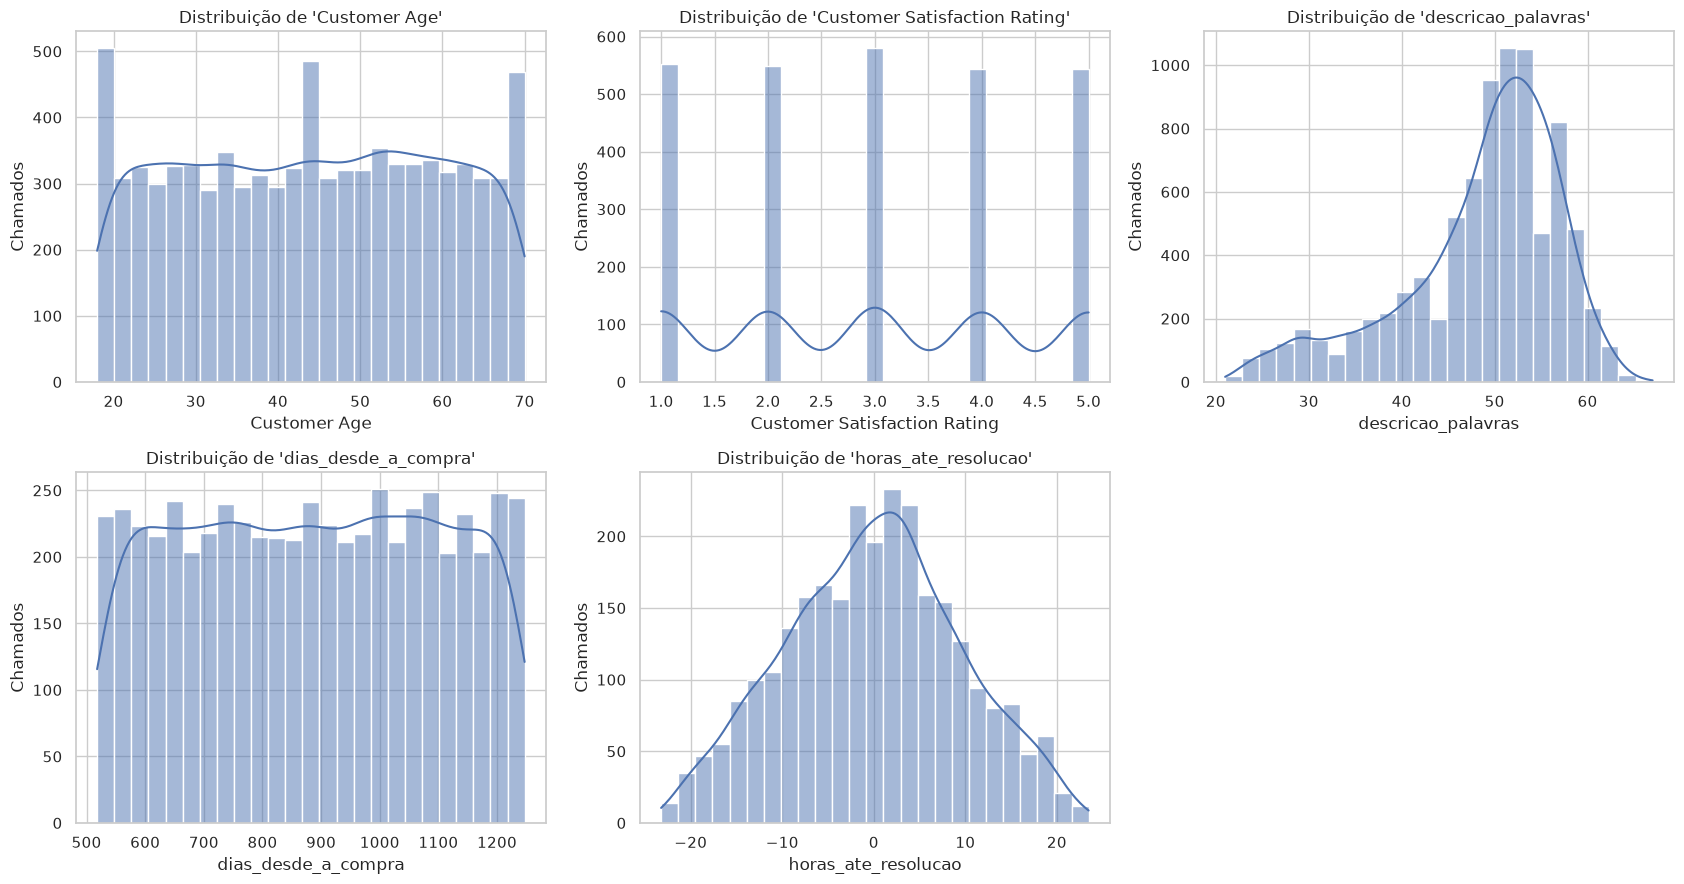

In [6]:
NUMERICAS = ["Customer Age", "Customer Satisfaction Rating", "descricao_palavras",
             "dias_desde_a_compra", "horas_ate_resolucao"]

titulo("Medidas de posição e dispersão")
resumo = pd.DataFrame({
    "n": df[NUMERICAS].count(),
    "média": df[NUMERICAS].mean().round(2),
    "mediana": df[NUMERICAS].median().round(2),
    "desvio-padrão": df[NUMERICAS].std().round(2),
    "mínimo": df[NUMERICAS].min().round(2),
    "Q1": df[NUMERICAS].quantile(0.25).round(2),
    "Q3": df[NUMERICAS].quantile(0.75).round(2),
    "máximo": df[NUMERICAS].max().round(2),
})
display(resumo)

fig, eixos = plt.subplots(2, 3, figsize=(17, 9))
for eixo, coluna in zip(eixos.flat, NUMERICAS):
    sns.histplot(df[coluna].dropna(), bins=25, kde=True, ax=eixo, color="#4c72b0")
    eixo.set_title(f"Distribuição de '{coluna}'")
    eixo.set_xlabel(coluna)
    eixo.set_ylabel("Chamados")
eixos.flat[-1].axis("off")
plt.tight_layout()
plt.show()

## Variáveis categóricas

In [7]:
CATEGORICAS = ["Ticket Type", "Ticket Subject", "Ticket Status", "Ticket Priority",
               "Ticket Channel", "Customer Gender", "Product Purchased"]

titulo("Quantidade de categorias em cada variável")
print(df[CATEGORICAS].nunique())

for coluna in CATEGORICAS:
    titulo(f"Distribuição de '{coluna}'")
    contagem = df[coluna].value_counts()
    percentual = (df[coluna].value_counts(normalize=True) * 100).round(2)
    tabela = pd.DataFrame({"chamados": contagem, "percentual (%)": percentual})
    display(tabela.head(10) if len(tabela) > 10 else tabela)
    if len(tabela) > 10:
        print(f"(mostrando as 10 primeiras de {len(tabela)} categorias)")
    print(f"Mais frequente: {contagem.index[0]} ({contagem.iloc[0]} chamados, "
          f"{percentual.iloc[0]:.1f}%)")
    print(f"Menos frequente: {contagem.index[-1]} ({contagem.iloc[-1]} chamados, "
          f"{percentual.iloc[-1]:.1f}%)")


Quantidade de categorias em cada variável
Ticket Type           5
Ticket Subject       16
Ticket Status         3
Ticket Priority       4
Ticket Channel        4
Customer Gender       3
Product Purchased    42
dtype: int64

Distribuição de 'Ticket Type'


,chamados,percentual (%)
Ticket Type,,
Refund request,1752,20.69
Technical issue,1747,20.63
Cancellation request,1695,20.01
Product inquiry,1641,19.38
Billing inquiry,1634,19.29


Mais frequente: Refund request (1752 chamados, 20.7%)
Menos frequente: Billing inquiry (1634 chamados, 19.3%)

Distribuição de 'Ticket Subject'


,chamados,percentual (%)
Ticket Subject,,
Refund request,576,6.80
Software bug,574,6.78
Product compatibility,567,6.70
Delivery problem,561,6.62
Hardware issue,547,6.46
Battery life,542,6.40
Network problem,539,6.36
Installation support,530,6.26
Product setup,529,6.25


(mostrando as 10 primeiras de 16 categorias)
Mais frequente: Refund request (576 chamados, 6.8%)
Menos frequente: Display issue (478 chamados, 5.6%)

Distribuição de 'Ticket Status'


...

Mais frequente: Email (2143 chamados, 25.3%)
Menos frequente: Chat (2073 chamados, 24.5%)

Distribuição de 'Customer Gender'


,chamados,percentual (%)
Customer Gender,,
Male,2896,34.20
Female,2887,34.09
Other,2686,31.72


Mais frequente: Male (2896 chamados, 34.2%)
Menos frequente: Other (2686 chamados, 31.7%)

Distribuição de 'Product Purchased'


,chamados,percentual (%)
Product Purchased,,
Canon EOS,240,2.83
GoPro Hero,228,2.69
Nest Thermostat,225,2.66
Philips Hue Lights,221,2.61
Amazon Echo,221,2.61
LG Smart TV,219,2.59
Sony Xperia,217,2.56
Roomba Robot Vacuum,216,2.55
LG OLED,213,2.52


(mostrando as 10 primeiras de 42 categorias)
Mais frequente: Canon EOS (240 chamados, 2.8%)
Menos frequente: Nintendo Switch (178 chamados, 2.1%)


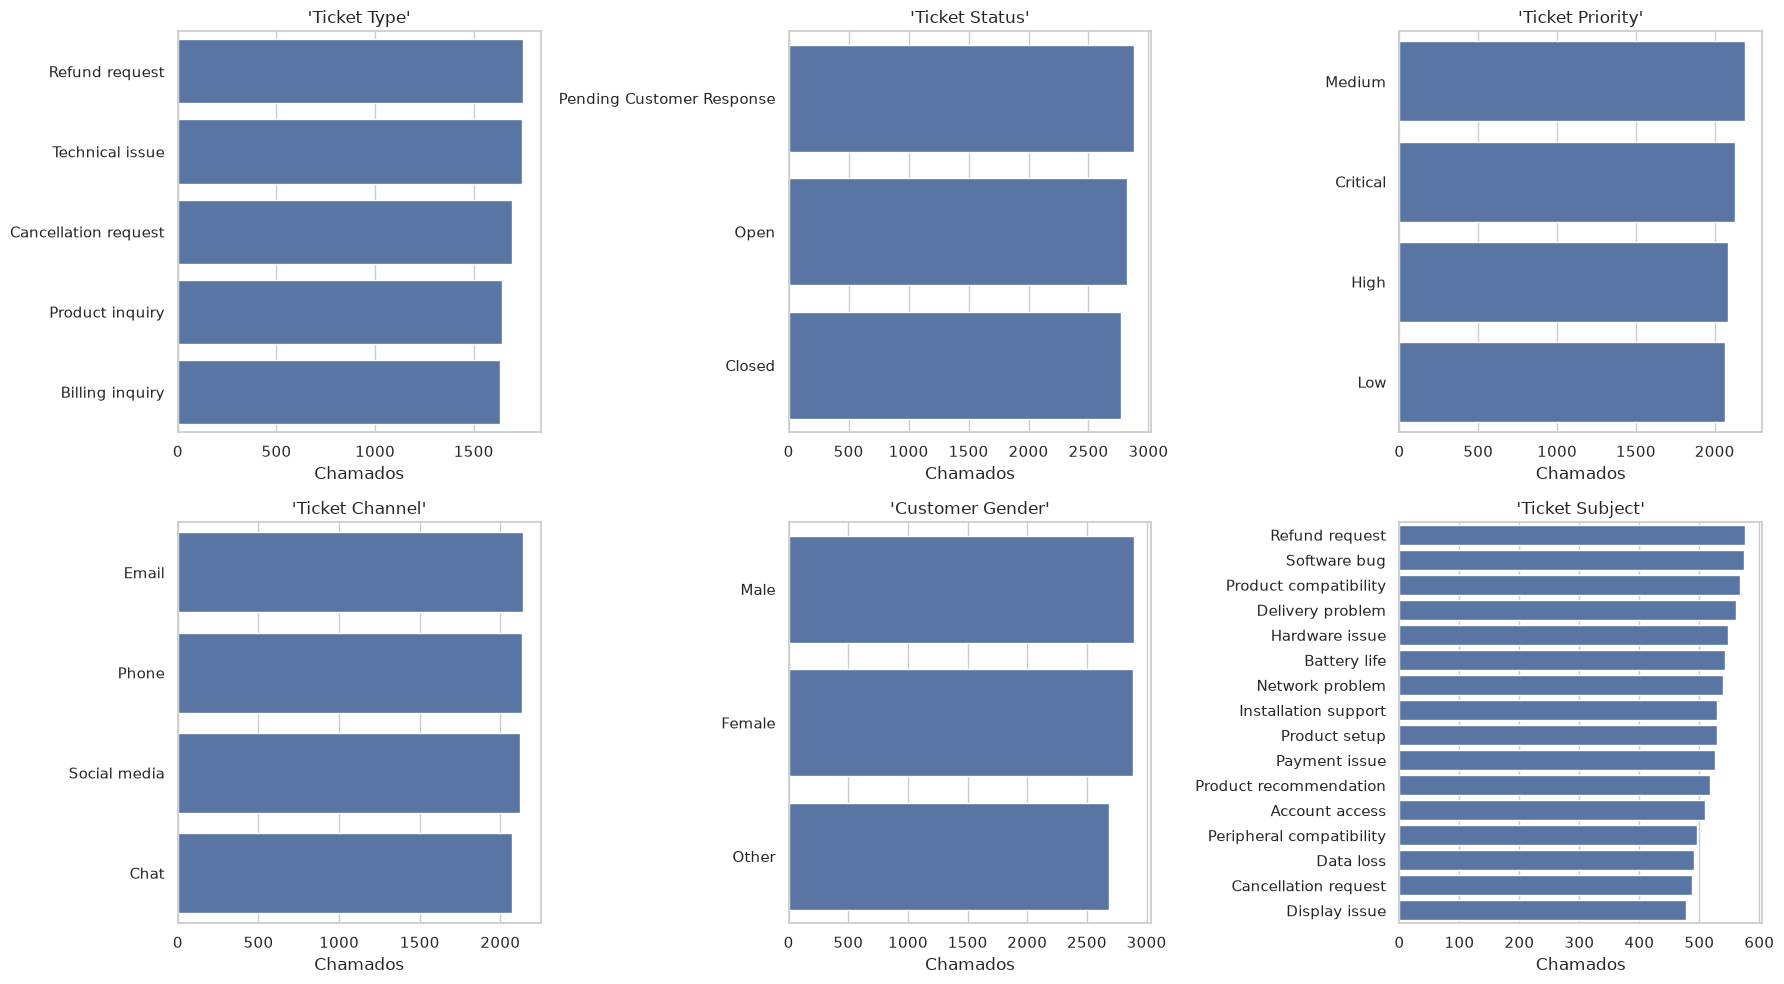

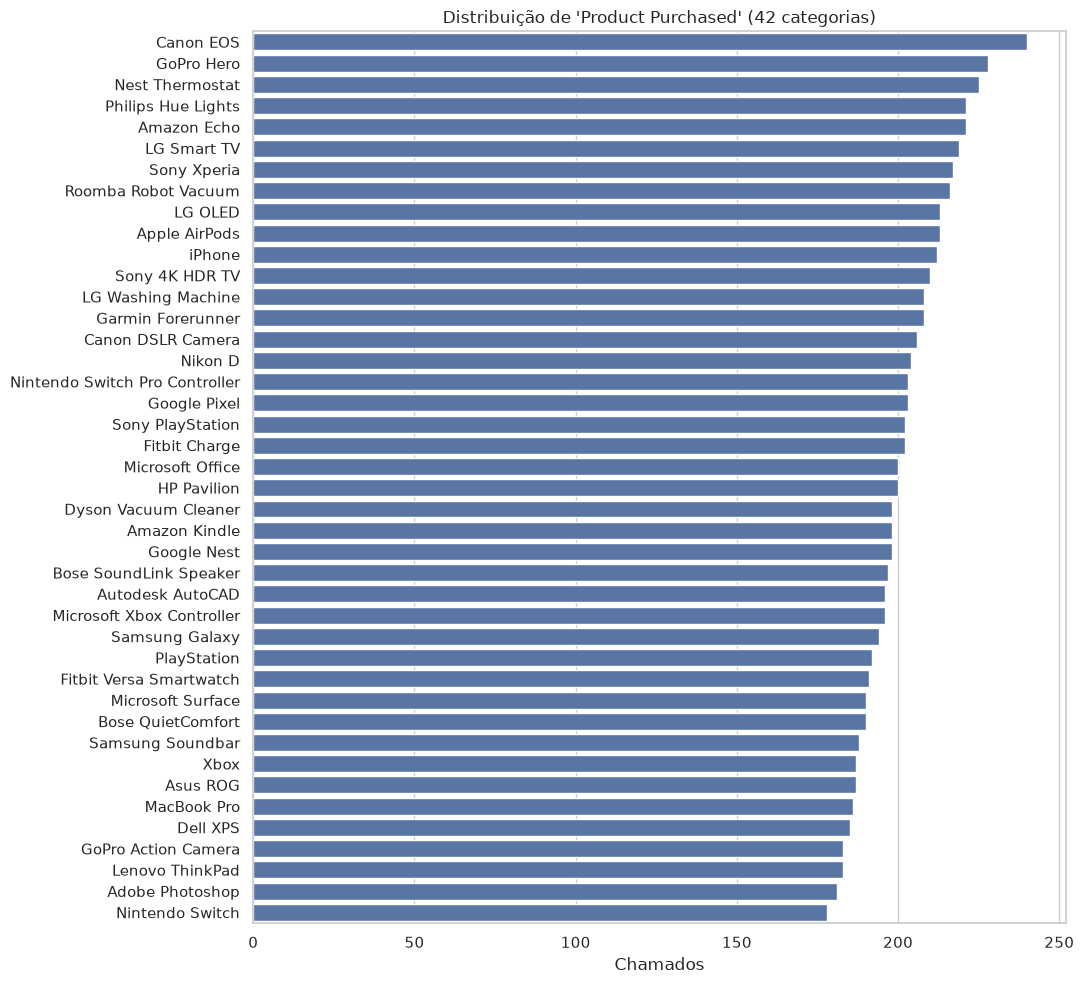

Produto mais frequente: Canon EOS (240)
Produto menos frequente: Nintendo Switch (178)
Razão entre o maior e o menor: 1.35x


In [8]:
PARA_PLOTAR = ["Ticket Type", "Ticket Status", "Ticket Priority", "Ticket Channel",
               "Customer Gender", "Ticket Subject"]

fig, eixos = plt.subplots(2, 3, figsize=(18, 10))
for eixo, coluna in zip(eixos.flat, PARA_PLOTAR):
    contagem = df[coluna].value_counts()
    sns.barplot(x=contagem.values, y=contagem.index.astype(str), ax=eixo, color="#4c72b0")
    eixo.set_title(f"'{coluna}'")
    eixo.set_xlabel("Chamados")
    eixo.set_ylabel("")
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 10))
contagem_produto = df["Product Purchased"].value_counts()
sns.barplot(x=contagem_produto.values, y=contagem_produto.index, color="#4c72b0")
plt.title("Distribuição de 'Product Purchased' (42 categorias)")
plt.xlabel("Chamados")
plt.ylabel("")
plt.tight_layout()
plt.show()

print(f"Produto mais frequente: {contagem_produto.index[0]} ({contagem_produto.iloc[0]})")
print(f"Produto menos frequente: {contagem_produto.index[-1]} ({contagem_produto.iloc[-1]})")
print(f"Razão entre o maior e o menor: {contagem_produto.iloc[0] / contagem_produto.iloc[-1]:.2f}x")

## Observações - análise univariada

### Variáveis numéricas

- **`Customer Age`**: espalhada quase por igual entre 18 e 70 anos (média ≈ 44, mediana ≈ 44). Não
  há concentração em nenhuma faixa etária - o que é estranho para uma base real de suporte de
  produtos de tecnologia, onde normalmente se vê predominância de alguma faixa.
- **`Customer Satisfaction Rating`**: existe só para os chamados fechados. As notas de 1 a 5
  aparecem praticamente na mesma proporção (média ≈ 2,99), sem o viés para notas altas ou para os
  extremos que costuma marcar pesquisa de satisfação real.
- **`descricao_palavras`**: textos entre 21 e 63 palavras, concentrados em torno de 46. A faixa é
  estreita demais para texto escrito espontaneamente por pessoas diferentes.
- **`horas_ate_resolucao`**: distribuição simétrica em torno de zero, com metade dos valores
  negativos - a anomalia que descrevemos na etapa 1.3, agora visível no histograma.

### Variáveis categóricas

Todas, sem exceção, aparecem muito próximas da distribuição uniforme:

| Variável | Categorias | Faixa de frequência |
|---|---|---|
| `Ticket Type` (alvo) | 5 | 19,3% a 20,7% |
| `Ticket Subject` | 16 | ~5,6% a ~6,8% |
| `Ticket Status` | 3 | 32,7% a 34,0% |
| `Ticket Priority` | 4 | 24,4% a 25,9% |
| `Ticket Channel` | 4 | ~24% a ~26% |
| `Customer Gender` | 3 | 31,7% a 34,2% |
| `Product Purchased` | 42 | 178 a 240 chamados cada |

`Product Purchased` segue o mesmo padrão: 42
produtos com frequências muito próximas, sendo o mais comum apenas 1,35 vez mais frequente que o
mais raro. Num catálogo real, alguns produtos geram muito mais chamados que outros.

Para a variável-alvo isso tem um lado bom: o dataset é perfeitamente balanceado, sem classe
rara nem classe dominante. Mas a uniformidade em *todas* as variáveis ao mesmo tempo é o padrão de
dados gerados por sorteio, não de dados coletados.

---

## Hipóteses sobre as intenções dos usuários

A partir desses padrões, formulamos três hipóteses de forma que cada 
uma vire uma comparação entre dois grupos, com um teste estatístico 
que a confirma ou derruba. Os testes estão na etapa 1.6.

> **H1 - O tipo de chamado não muda o esforço que o cliente coloca na mensagem.**
> Se as cinco intenções ocorrem com a mesma frequência e nenhuma domina, esperamos também que o
> cliente não escreva sistematicamente mais em um tipo do que em outro.
> *Forma testável:* o número de palavras da descrição é igual entre `Refund request` (o tipo mais
> frequente) e `Billing inquiry` (o menos frequente)?

> **H2 - Chamados de frustração pós-compra deixam o cliente mais insatisfeito que dúvidas simples.**
> `Refund request` e `Technical issue` representam algo deu errado depois da compra;
> `Product inquiry` é uma dúvida, sem prejuízo envolvido. É razoável esperar notas piores no
> primeiro grupo.
> *Forma testável:* a nota de satisfação é menor em `Refund request` + `Technical issue` do que em
> `Product inquiry`?

> **H3 - A prioridade atribuída ao chamado não se reflete na experiência final do cliente.**
> Esta é a hipótese que o professor pediu para tratar melhor. Não basta observar que
> `Ticket Priority` e `Ticket Type` são ambas uniformes: isso é distribuição marginal e não diz
> nada sobre a relação entre as duas. Precisamos de um teste que olhe as duas juntas.
> *Forma testável:* (a) a nota de satisfação difere entre chamados `Critical` e `Low`? e
> (b) existe associação entre `Ticket Priority` e `Ticket Type` num teste qui-quadrado de
> independência?

---
# 1.6 Análise Multivariada

Agora olhamos as variáveis em conjunto: quem se relaciona com quem, e com que intensidade.

## 1.6.1 Correlação entre as variáveis numéricas

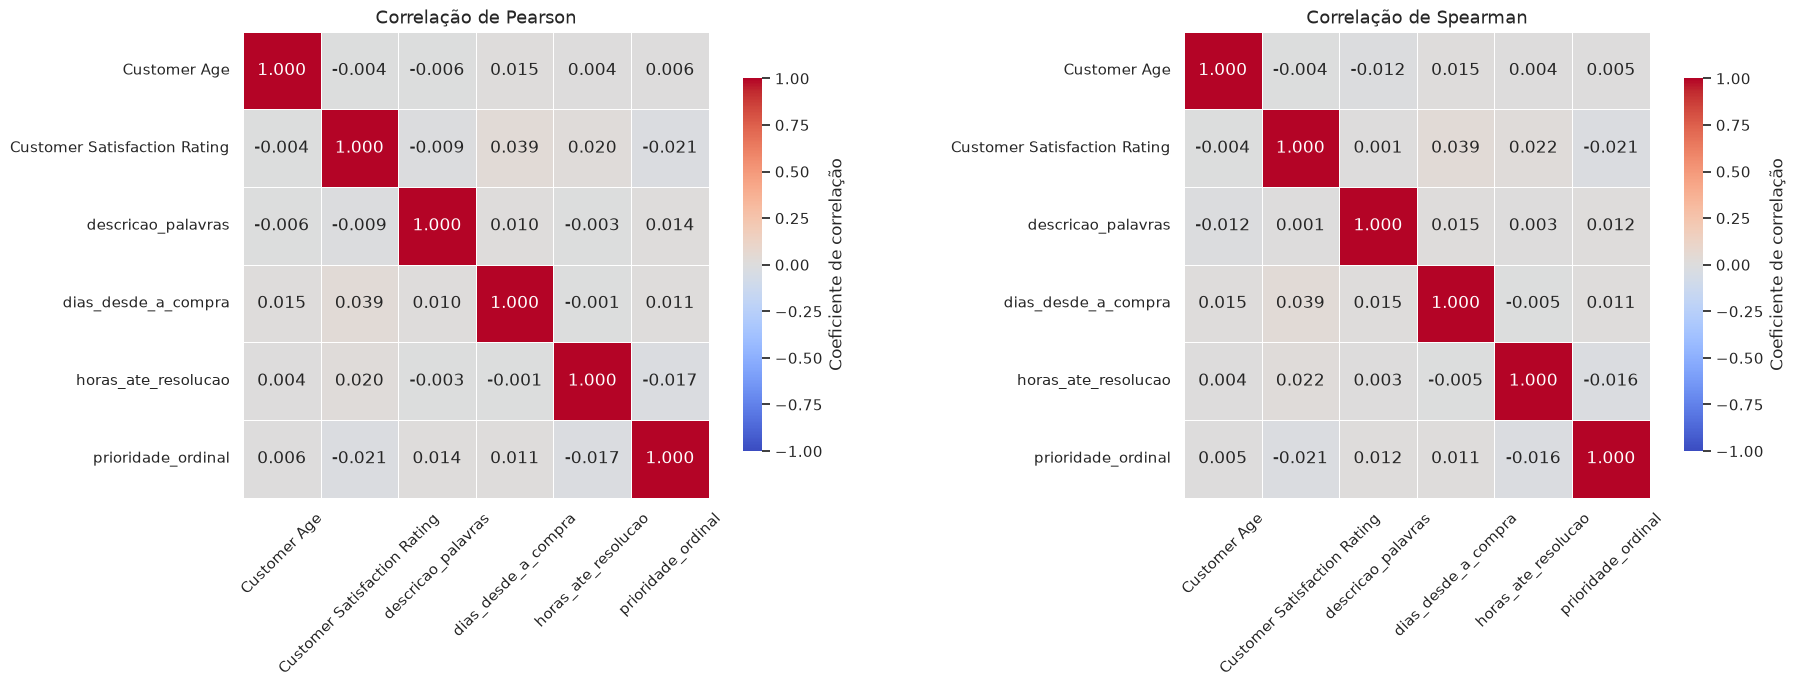


Correlações ordenadas da mais forte para a mais fraca
|r| = 0.0385   Customer Satisfaction Rating  x  dias_desde_a_compra
|r| = 0.0214   Customer Satisfaction Rating  x  prioridade_ordinal
|r| = 0.0199   Customer Satisfaction Rating  x  horas_ate_resolucao
|r| = 0.0170   horas_ate_resolucao  x  prioridade_ordinal
|r| = 0.0150   Customer Age  x  dias_desde_a_compra
|r| = 0.0141   descricao_palavras  x  prioridade_ordinal
|r| = 0.0112   dias_desde_a_compra  x  prioridade_ordinal
|r| = 0.0103   descricao_palavras  x  dias_desde_a_compra
|r| = 0.0086   Customer Satisfaction Rating  x  descricao_palavras
|r| = 0.0064   Customer Age  x  descricao_palavras
|r| = 0.0058   Customer Age  x  prioridade_ordinal
|r| = 0.0043   Customer Age  x  horas_ate_resolucao
|r| = 0.0037   Customer Age  x  Customer Satisfaction Rating
|r| = 0.0033   descricao_palavras  x  horas_ate_resolucao
|r| = 0.0012   dias_desde_a_compra  x  horas_ate_resolucao

Correlação mais forte do dataset: |r| = 0.0385

Escala de C

In [9]:
PARA_CORRELACAO = ["Customer Age", "Customer Satisfaction Rating", "descricao_palavras",
                   "dias_desde_a_compra", "horas_ate_resolucao", "prioridade_ordinal"]

pearson = df[PARA_CORRELACAO].corr(method="pearson")
spearman = df[PARA_CORRELACAO].corr(method="spearman")

fig, eixos = plt.subplots(1, 2, figsize=(19, 7))
for eixo, (matriz, nome) in zip(eixos, [(pearson, "Pearson"), (spearman, "Spearman")]):
    sns.heatmap(
        matriz, annot=True, fmt=".3f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
        square=True, linewidths=0.5, ax=eixo,
        cbar_kws={"shrink": 0.8, "label": "Coeficiente de correlação"},
    )
    eixo.set_title(f"Correlação de {nome}", fontsize=13)
    eixo.tick_params(axis="x", rotation=45)
    eixo.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

titulo("Correlações ordenadas da mais forte para a mais fraca")
pares = [
    (abs(pearson.loc[a, b]), a, b)
    for i, a in enumerate(PARA_CORRELACAO)
    for b in PARA_CORRELACAO[i + 1:]
]
for valor, a, b in sorted(pares, reverse=True):
    print(f"|r| = {valor:.4f}   {a}  x  {b}")

print(f"\nCorrelação mais forte do dataset: |r| = {max(pares)[0]:.4f}")
print("\nEscala de Cohen: |r| < 0,10 desprezível | 0,10-0,29 fraca | "
      "0,30-0,49 moderada | >= 0,50 forte")

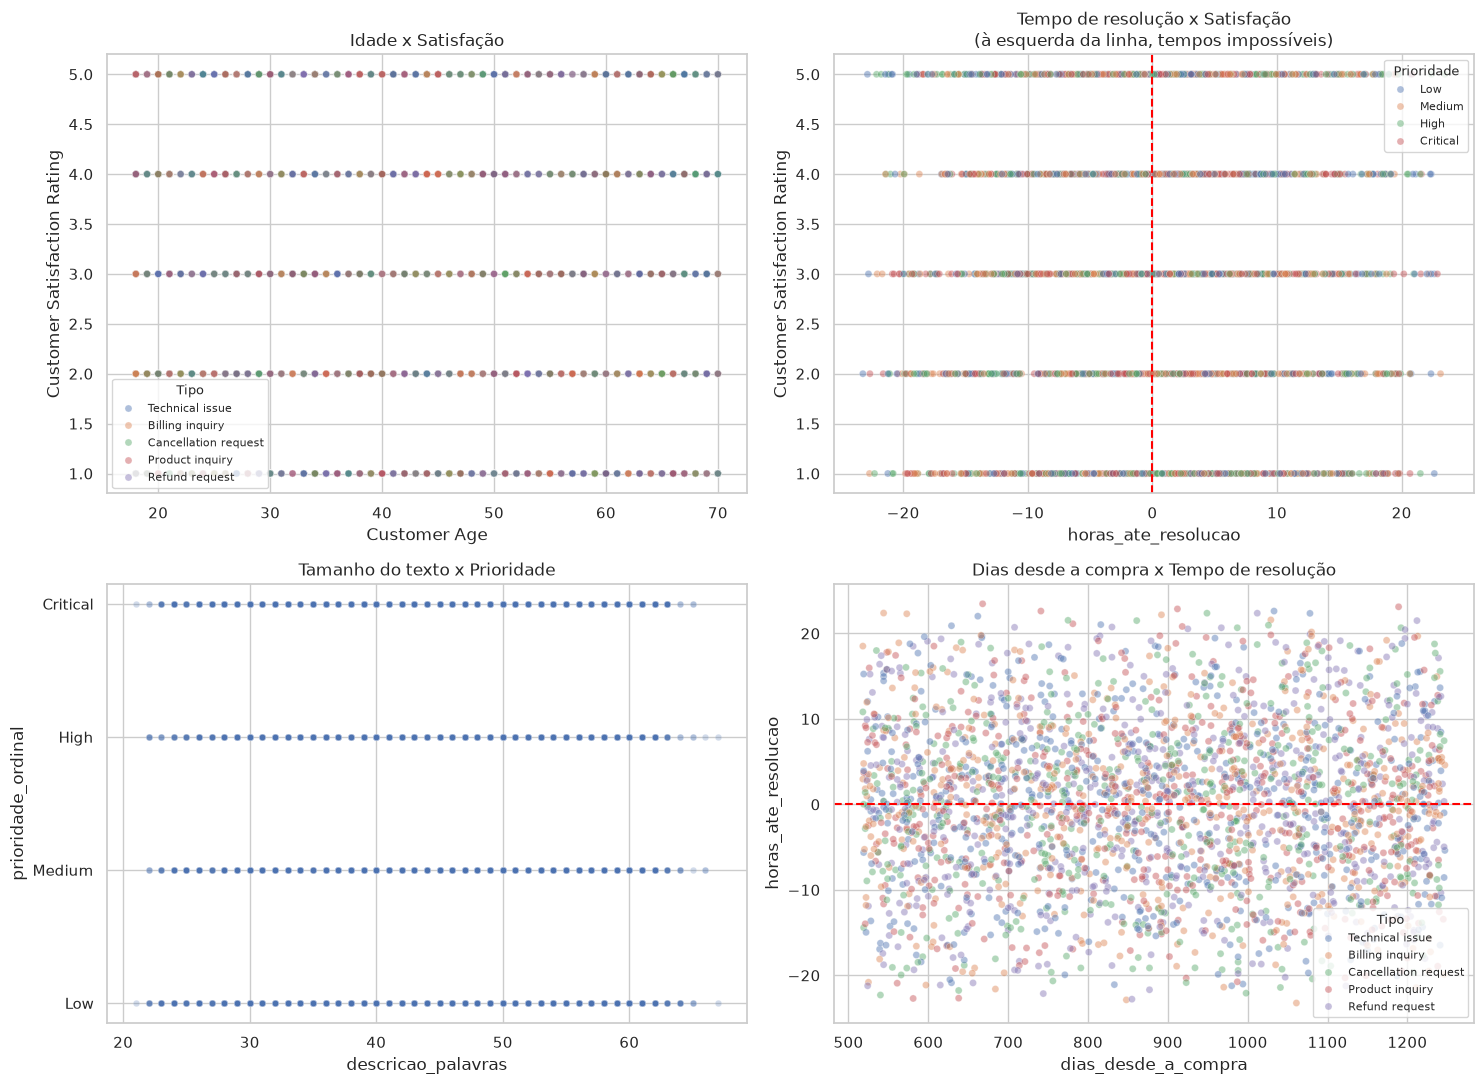

In [10]:
fig, eixos = plt.subplots(2, 2, figsize=(15, 11))

sns.scatterplot(data=df, x="Customer Age", y="Customer Satisfaction Rating",
                hue="Ticket Type", alpha=0.45, s=26, ax=eixos[0, 0])
eixos[0, 0].set_title("Idade x Satisfação")
eixos[0, 0].legend(title="Tipo", fontsize=8, title_fontsize=9)

sns.scatterplot(data=df, x="horas_ate_resolucao", y="Customer Satisfaction Rating",
                hue="Ticket Priority", hue_order=["Low", "Medium", "High", "Critical"],
                alpha=0.45, s=26, ax=eixos[0, 1])
eixos[0, 1].axvline(0, color="red", linestyle="--", linewidth=1.5)
eixos[0, 1].set_title("Tempo de resolução x Satisfação\n(à esquerda da linha, tempos impossíveis)")
eixos[0, 1].legend(title="Prioridade", fontsize=8, title_fontsize=9)

sns.scatterplot(data=df, x="descricao_palavras", y="prioridade_ordinal",
                alpha=0.25, s=22, color="#4c72b0", ax=eixos[1, 0])
eixos[1, 0].set_yticks([1, 2, 3, 4])
eixos[1, 0].set_yticklabels(["Low", "Medium", "High", "Critical"])
eixos[1, 0].set_title("Tamanho do texto x Prioridade")

sns.scatterplot(data=df, x="dias_desde_a_compra", y="horas_ate_resolucao",
                hue="Ticket Type", alpha=0.45, s=26, ax=eixos[1, 1])
eixos[1, 1].axhline(0, color="red", linestyle="--", linewidth=1.5)
eixos[1, 1].set_title("Dias desde a compra x Tempo de resolução")
eixos[1, 1].legend(title="Tipo", fontsize=8, title_fontsize=9)

plt.tight_layout()
plt.show()

## 1.6.2 Relação entre as variáveis categóricas


Ticket Priority x Ticket Type - a hipótese H3
Tabela cruzada (contagem de chamados):


Ticket Type,Billing inquiry,Cancellation request,Product inquiry,Refund request,Technical issue
Ticket Priority,,,,,
Critical,420,423,403,444,439
High,382,398,399,448,458
Low,398,414,398,440,413
Medium,434,460,441,420,437


Qui-quadrado = 10.63  |  graus de liberdade = 12  |  p-valor = 0.5613
V de Cramér  = 0.0205   (0 = independência total, 1 = associação perfeita)

p > 0,05: não rejeitamos a independência. Prioridade e tipo de chamado
não estão associados - agora demonstrado com um teste bivariado, e não
apenas observando as distribuições separadas.

Ticket Subject x Ticket Type
Qui-quadrado = 39.57  |  graus de liberdade = 60  |  p-valor = 0.9807
V de Cramér  = 0.0342

Este resultado é ainda mais revelador: o ASSUNTO declarado do chamado não
tem relação com o TIPO do chamado. Num dataset coerente, um chamado com
assunto 'Cancellation request' seria quase sempre do tipo 'Cancellation request'.


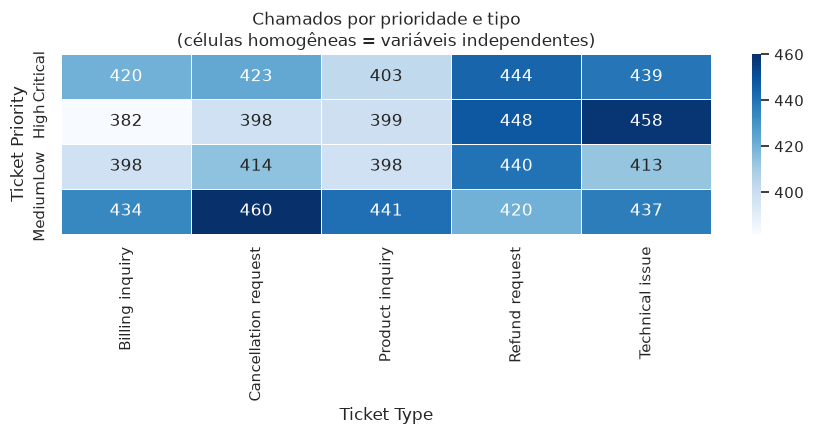

In [11]:
def testar_independencia(coluna_a, coluna_b):
    """Qui-quadrado de independência + V de Cramér entre duas categóricas."""
    tabela = pd.crosstab(df[coluna_a], df[coluna_b])
    qui2, p, graus, _ = stats.chi2_contingency(tabela)
    n = tabela.to_numpy().sum()
    cramers_v = np.sqrt((qui2 / n) / (min(tabela.shape) - 1))
    return tabela, qui2, p, graus, cramers_v


titulo("Ticket Priority x Ticket Type - a hipótese H3")
tabela, qui2, p, graus, v = testar_independencia("Ticket Priority", "Ticket Type")
print("Tabela cruzada (contagem de chamados):")
display(tabela)
print(f"Qui-quadrado = {qui2:.2f}  |  graus de liberdade = {graus}  |  p-valor = {p:.4f}")
print(f"V de Cramér  = {v:.4f}   (0 = independência total, 1 = associação perfeita)")
print()
if p > 0.05:
    print("p > 0,05: não rejeitamos a independência. Prioridade e tipo de chamado")
    print("não estão associados - agora demonstrado com um teste bivariado, e não")
    print("apenas observando as distribuições separadas.")

titulo("Ticket Subject x Ticket Type")
tabela2, qui2_b, p_b, graus_b, v_b = testar_independencia("Ticket Subject", "Ticket Type")
print(f"Qui-quadrado = {qui2_b:.2f}  |  graus de liberdade = {graus_b}  |  p-valor = {p_b:.4f}")
print(f"V de Cramér  = {v_b:.4f}")
print()
print("Este resultado é ainda mais revelador: o ASSUNTO declarado do chamado não")
print("tem relação com o TIPO do chamado. Num dataset coerente, um chamado com")
print("assunto 'Cancellation request' seria quase sempre do tipo 'Cancellation request'.")

plt.figure(figsize=(9, 4.5))
sns.heatmap(pd.crosstab(df["Ticket Priority"], df["Ticket Type"]),
            annot=True, fmt="d", cmap="Blues", linewidths=0.5)
plt.title("Chamados por prioridade e tipo\n(células homogêneas = variáveis independentes)")
plt.tight_layout()
plt.show()

## 1.6.3 Testes de hipótese formais

In [12]:
ALFA = 0.05

titulo("Verificação de normalidade (Shapiro-Wilk)")
fechados = df[df["Ticket Status"] == "Closed"]
for nome, amostra in [
    ("Satisfação (Critical)",
     fechados.loc[fechados["Ticket Priority"] == "Critical",
                  "Customer Satisfaction Rating"].dropna()),
    ("Satisfação (Low)",
     fechados.loc[fechados["Ticket Priority"] == "Low",
                  "Customer Satisfaction Rating"].dropna()),
    ("Palavras (Refund request)",
     df.loc[df["Ticket Type"] == "Refund request", "descricao_palavras"].dropna()),
]:
    sub = amostra.sample(min(500, len(amostra)), random_state=42)
    w, p_shapiro = stats.shapiro(sub)
    print(f"{nome:28s}: W = {w:.4f} | p = {p_shapiro:.2e} | "
          f"normal? {'sim' if p_shapiro > ALFA else 'NÃO'}")

print("\nNenhuma das variáveis é normal - o que já era esperado, já que a satisfação")
print("é uma escala discreta de 1 a 5. Por isso o teste principal de cada hipótese é")
print("o Mann-Whitney U, que não exige normalidade. Rodamos o teste t de Welch em")
print("paralelo apenas para confirmar que a conclusão não depende dessa escolha.")


def testar_hipotese(titulo_teste, grupo_a, nome_a, grupo_b, nome_b):
    """Roda Mann-Whitney + Welch e imprime tudo de forma legível."""
    titulo(titulo_teste)

    resumo = pd.DataFrame({
        nome_a: [len(grupo_a), grupo_a.mean(), grupo_a.median(), grupo_a.std()],
        nome_b: [len(grupo_b), grupo_b.mean(), grupo_b.median(), grupo_b.std()],
    }, index=["n", "média", "mediana", "desvio-padrão"])
    display(resumo.round(4))

    u, p_mw = stats.mannwhitneyu(grupo_a, grupo_b, alternative="two-sided")
    r = 1 - (2 * u) / (len(grupo_a) * len(grupo_b))
    t, p_t = stats.ttest_ind(grupo_a, grupo_b, equal_var=False)

    print(f"Mann-Whitney U : U = {u:,.1f}  |  p-valor = {p_mw:.4f}")
    print(f"Tamanho de efeito (rank-biserial): r = {r:.4f}")
    print(f"Teste t de Welch: t = {t:.4f}  |  p-valor = {p_t:.4f}")
    print()
    if p_mw < ALFA:
        print(f"p < {ALFA}: REJEITAMOS a hipótese nula - há diferença entre os grupos.")
    else:
        print(f"p > {ALFA}: NÃO rejeitamos a hipótese nula - não há evidência de diferença.")
    return p_mw, r


Verificação de normalidade (Shapiro-Wilk)
Satisfação (Critical)       : W = 0.8825 | p = 4.82e-19 | normal? NÃO
Satisfação (Low)            : W = 0.8865 | p = 1.02e-18 | normal? NÃO
Palavras (Refund request)   : W = 0.9410 | p = 3.43e-13 | normal? NÃO

Nenhuma das variáveis é normal - o que já era esperado, já que a satisfação
é uma escala discreta de 1 a 5. Por isso o teste principal de cada hipótese é
o Mann-Whitney U, que não exige normalidade. Rodamos o teste t de Welch em
paralelo apenas para confirmar que a conclusão não depende dessa escolha.


In [13]:
# ---------------------------------------------------------------- H1
# H0: o número de palavras é igual entre Refund request e Billing inquiry
# H1: as distribuições diferem
p_h1, r_h1 = testar_hipotese(
    "H1 - O tipo de chamado muda o tamanho do texto que o cliente escreve?",
    df.loc[df["Ticket Type"] == "Refund request", "descricao_palavras"].dropna(),
    "Refund request",
    df.loc[df["Ticket Type"] == "Billing inquiry", "descricao_palavras"].dropna(),
    "Billing inquiry",
)


H1 - O tipo de chamado muda o tamanho do texto que o cliente escreve?


,Refund request,Billing inquiry
n,1752.0000,1634.0000
média,48.6895,48.6359
mediana,51.0000,50.0000
desvio-padrão,8.6152,8.4575


Mann-Whitney U : U = 1,448,109.5  |  p-valor = 0.5559
Tamanho de efeito (rank-biserial): r = -0.0117
Teste t de Welch: t = 0.1827  |  p-valor = 0.8550

p > 0.05: NÃO rejeitamos a hipótese nula - não há evidência de diferença.


In [14]:
# ---------------------------------------------------------------- H2
# H0: a satisfação é igual entre chamados de frustração e de dúvida
# H1: as distribuições diferem
frustracao = fechados.loc[
    fechados["Ticket Type"].isin(["Refund request", "Technical issue"]),
    "Customer Satisfaction Rating",
].dropna()
duvida = fechados.loc[
    fechados["Ticket Type"] == "Product inquiry", "Customer Satisfaction Rating"
].dropna()

p_h2, r_h2 = testar_hipotese(
    "H2 - Frustração pós-compra gera nota pior que dúvida sobre o produto?",
    frustracao, "Refund + Technical",
    duvida, "Product inquiry",
)


H2 - Frustração pós-compra gera nota pior que dúvida sobre o produto?


,Refund + Technical,Product inquiry
n,1176.0000,533.0000
média,2.9464,3.0169
mediana,3.0000,3.0000
desvio-padrão,1.4153,1.3661


Mann-Whitney U : U = 304,250.5  |  p-valor = 0.3228
Tamanho de efeito (rank-biserial): r = 0.0292
Teste t de Welch: t = -0.9766  |  p-valor = 0.3290

p > 0.05: NÃO rejeitamos a hipótese nula - não há evidência de diferença.



H3 - A prioridade do chamado se reflete na satisfação do cliente?


,Critical,Low
n,726.0000,644.0000
média,2.9587,3.0528
mediana,3.0000,3.0000
desvio-padrão,1.4165,1.3944


Mann-Whitney U : U = 224,913.5  |  p-valor = 0.2161
Tamanho de efeito (rank-biserial): r = 0.0379
Teste t de Welch: t = -1.2376  |  p-valor = 0.2161

p > 0.05: NÃO rejeitamos a hipótese nula - não há evidência de diferença.


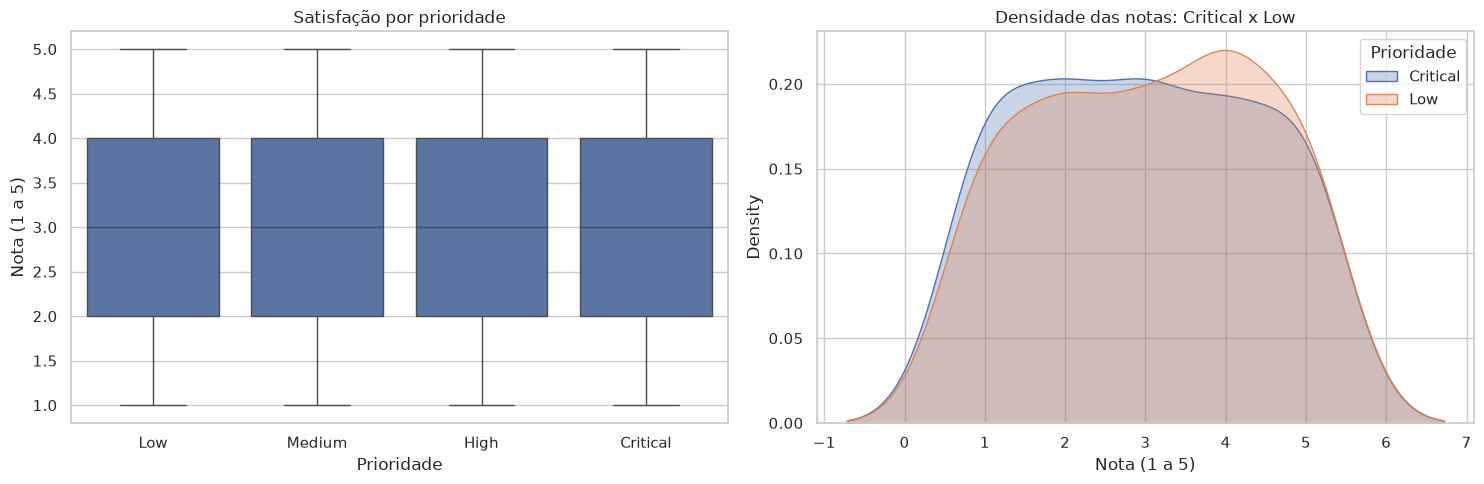

In [15]:
# ---------------------------------------------------------------- H3
# H0: a satisfação é igual entre chamados Critical e Low
# H1: as distribuições diferem
p_h3, r_h3 = testar_hipotese(
    "H3 - A prioridade do chamado se reflete na satisfação do cliente?",
    fechados.loc[fechados["Ticket Priority"] == "Critical",
                 "Customer Satisfaction Rating"].dropna(),
    "Critical",
    fechados.loc[fechados["Ticket Priority"] == "Low",
                 "Customer Satisfaction Rating"].dropna(),
    "Low",
)

# Visualização de apoio
fig, eixos = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=fechados, x="Ticket Priority", y="Customer Satisfaction Rating",
            order=["Low", "Medium", "High", "Critical"], ax=eixos[0])
eixos[0].set_title("Satisfação por prioridade")
eixos[0].set_xlabel("Prioridade")
eixos[0].set_ylabel("Nota (1 a 5)")

for grupo, rotulo in [
    (fechados.loc[fechados["Ticket Priority"] == "Critical",
                  "Customer Satisfaction Rating"].dropna(), "Critical"),
    (fechados.loc[fechados["Ticket Priority"] == "Low",
                  "Customer Satisfaction Rating"].dropna(), "Low"),
]:
    sns.kdeplot(grupo, label=rotulo, fill=True, alpha=0.3, bw_adjust=1.5, ax=eixos[1])
eixos[1].set_title("Densidade das notas: Critical x Low")
eixos[1].set_xlabel("Nota (1 a 5)")
eixos[1].legend(title="Prioridade")
plt.tight_layout()
plt.show()

## Observações - análise multivariada

### Correlação: o heatmap é branco

A correlação mais forte entre variáveis numéricas distintas é |r| ≈ 0,04, bem abaixo do 0,10
que a escala de Cohen usa como piso para chamar uma correlação de *fraca*. Na prática, nenhuma
variável numérica ajuda a prever nenhuma outra.

Num sistema real de atendimento esperaríamos ver pelo menos algumas relações intuitivas: chamados
críticos resolvidos mais rápido, tempos longos derrubando a satisfação, clientes mais antigos
reclamando de coisas diferentes. Não há nada disso.

Os scatter plots confirmam visualmente: todos produzem nuvens retangulares homogêneas, sem
inclinação, sem agrupamentos, sem regiões vazias. É o desenho de variáveis independentes.

### Categóricas: independentes também

| Par testado | Qui-quadrado | p-valor | V de Cramér | Conclusão |
|---|---|---|---|---|
| `Ticket Priority` × `Ticket Type` | 10,63 (12 g.l.) | **0,561** | 0,021 | Independentes |
| `Ticket Subject` × `Ticket Type` | 39,57 (60 g.l.) | **0,981** | 0,034 | Independentes |

O primeiro resultado responde à ressalva do professor sobre a H3: agora temos um teste bivariado
de verdade sustentando a afirmação de independência, e não apenas a observação de que as duas
distribuições marginais são uniformes.

O segundo é mais grave para o projeto. `Ticket Subject` é o assunto declarado do chamado - um
chamado com assunto "Cancellation request" deveria ser, quase sempre, do tipo
"Cancellation request". Aqui ele se espalha igualmente pelos cinco tipos.

### Os três testes de hipótese

| Hipótese | Comparação | p-valor (Mann-Whitney) | Efeito (r) | Resultado |
|---|---|---|---|---|
| **H1** | Palavras: Refund × Billing | **0,556** | -0,012 | H₀ não rejeitada |
| **H2** | Satisfação: frustração × dúvida | **0,323** | 0,029 | H₀ não rejeitada |
| **H3** | Satisfação: Critical × Low | **0,216** | 0,038 | H₀ não rejeitada |

**Como ler esses p-valores, em português:** o p-valor responde à pergunta *"se os dois grupos
fossem realmente iguais, qual seria a chance de eu observar, só por sorte, uma diferença tão
grande quanto a que medi?"*. Em H3, a resposta é 21,6% - uma chance alta. Como se costuma
exigir menos de 5% para afirmar que uma diferença é real, não temos evidência de diferença nenhuma.

E não é só o p-valor: os tamanhos de efeito são todos próximos de zero (|r| ≤ 0,04). Isso
importa porque, com amostras grandes, até diferenças ridículas viram "estatisticamente
significativas". Aqui não é o caso - a diferença não é significativa **e** é minúscula. Em H3, por
exemplo, a nota média foi 2,96 para chamados críticos e 3,05 para os de baixa prioridade: menos de
0,1 ponto numa escala de 1 a 5.

O teste t de Welch chegou à mesma conclusão nos três casos - nenhuma diferença significativa -,
ainda que com p-valores diferentes do Mann-Whitney em H1 (0,855 contra 0,556) e H2 (0,329 contra
0,323). Em H3 os dois coincidiram (0,216). A divergência em H1 é esperada: os dois testes medem
coisas distintas (o t compara médias, o Mann-Whitney compara postos), e `descricao_palavras` tem
uma distribuição bem longe da normal. O que importa é que a decisão estatística não muda conforme
o teste escolhido.

### Conectando com o que esperávamos no TP1

As três hipóteses que formulamos se comportaram assim:

- **H1 e H3 foram sustentadas**, mas por um motivo diferente do que imaginávamos. Achávamos que
  estávamos descrevendo um traço do comportamento dos clientes ("as intenções são diversas", "a
  urgência não define o desfecho"). O que os testes mostram é mais simples: as variáveis não se
  relacionam porque foram sorteadas separadamente.
- **H2 não se sustentou.** Esperávamos que pedido de reembolso e problema técnico deixassem o
  cliente mais insatisfeito que uma dúvida sobre produto. A diferença observada foi de 0,07 ponto,
  com p = 0,323. Num dataset real essa hipótese teria boa chance de se confirmar; aqui ela não tem
  como, porque a nota de satisfação não foi gerada a partir do que aconteceu no chamado.

---
# 1.7 Identificação de Outliers e Anomalias

Separamos duas coisas que costumam ser tratadas juntas:

- **Outliers** são valores extremos dentro de uma distribuição - o cliente de 70 anos, a nota 1.
  São legítimos, só estão na ponta.
- **Anomalias** são valores que não deveriam existir de jeito nenhum - um chamado resolvido antes
  de ser respondido. Essas indicam defeito nos dados.

A segunda categoria é a que realmente importa neste dataset.


1. Outliers pelo método do IQR (intervalo interquartil)


,variável,n,limite inferior,limite superior,outliers,% do total
0,Customer Age,8469,-8.00,96.00,0,0.00
1,Customer Satisfaction Rating,2769,-1.00,7.00,0,0.00
2,descricao_palavras,8469,30.00,70.00,417,4.92
3,dias_desde_a_compra,5650,150.12,1617.12,0,0.00
4,horas_ate_resolucao,2769,-27.06,26.61,0,0.00


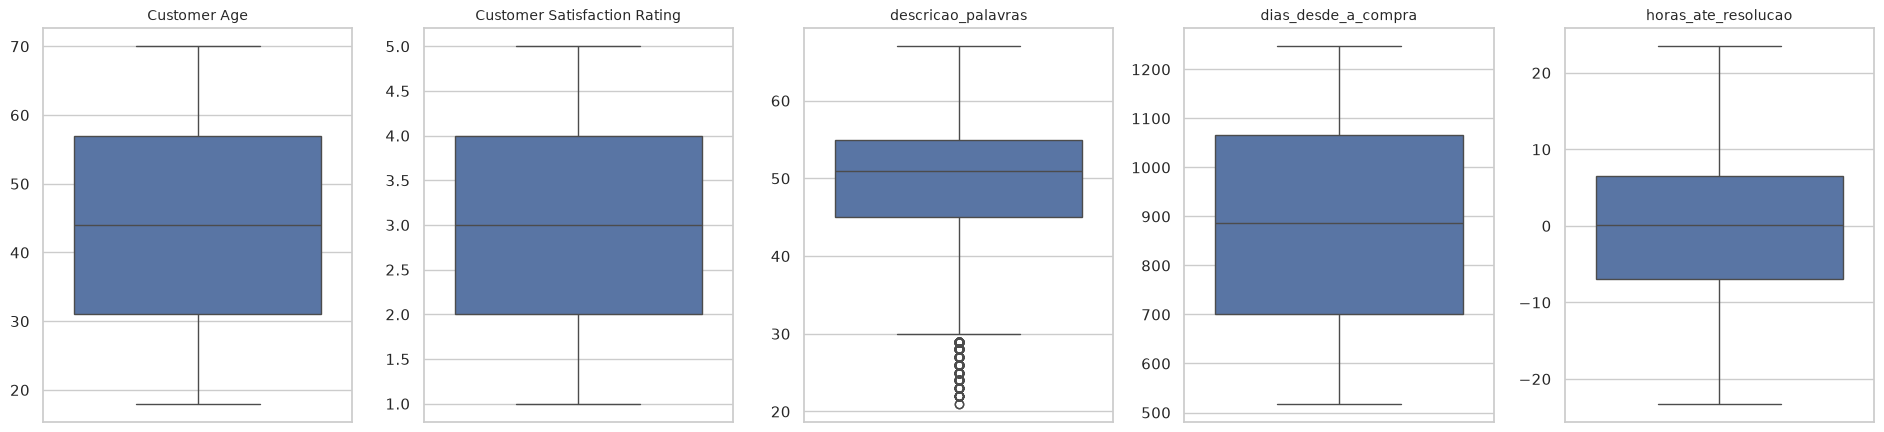


2. Outliers pelo escore-z (|z| > 3)
Customer Age                  :    0 valores com |z| > 3
Customer Satisfaction Rating  :    0 valores com |z| > 3
descricao_palavras            :   18 valores com |z| > 3
dias_desde_a_compra           :    0 valores com |z| > 3
horas_ate_resolucao           :    0 valores com |z| > 3


In [16]:
titulo("1. Outliers pelo método do IQR (intervalo interquartil)")

def contar_outliers(serie):
    """Regra clássica: fora de [Q1 - 1,5*IQR, Q3 + 1,5*IQR]."""
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    limite_baixo, limite_alto = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    fora = serie[(serie < limite_baixo) | (serie > limite_alto)]
    return len(fora), limite_baixo, limite_alto


linhas = []
for coluna in NUMERICAS:
    serie = df[coluna].dropna()
    quantidade, baixo, alto = contar_outliers(serie)
    linhas.append({
        "variável": coluna,
        "n": len(serie),
        "limite inferior": round(baixo, 2),
        "limite superior": round(alto, 2),
        "outliers": quantidade,
        "% do total": round(quantidade / len(serie) * 100, 2),
    })
display(pd.DataFrame(linhas))

fig, eixos = plt.subplots(1, 5, figsize=(19, 4.5))
for eixo, coluna in zip(eixos, NUMERICAS):
    sns.boxplot(y=df[coluna].dropna(), ax=eixo, color="#4c72b0")
    eixo.set_title(coluna, fontsize=10)
    eixo.set_ylabel("")
plt.tight_layout()
plt.show()

titulo("2. Outliers pelo escore-z (|z| > 3)")
for coluna in NUMERICAS:
    serie = df[coluna].dropna()
    z = np.abs(stats.zscore(serie))
    print(f"{coluna:30s}: {(z > 3).sum():4d} valores com |z| > 3")


3. ANOMALIAS - valores que não deveriam existir
3.1 Chamados resolvidos ANTES da primeira resposta
     1365 chamados (49.3% dos fechados)
     Tempo mais negativo registrado: -23.2 horas

3.2 Placeholder não substituído nas descrições
     8469 de 8469 descrições (100%)

3.3 Descrições repetidas
     392 descrições repetem outra já existente
     5868 chamados (69.3%) começam com
     exatamente o mesmo texto: "I'm having an issue with the {product_purchased}. Please assist."

     E esses chamados se distribuem assim entre as cinco intenções:
Ticket Type
Technical issue         1231
Refund request          1217
Cancellation request    1175
Billing inquiry         1124
Product inquiry         1121

3.4 Satisfação registrada em chamado não fechado
     0 chamados (esperado: 0)


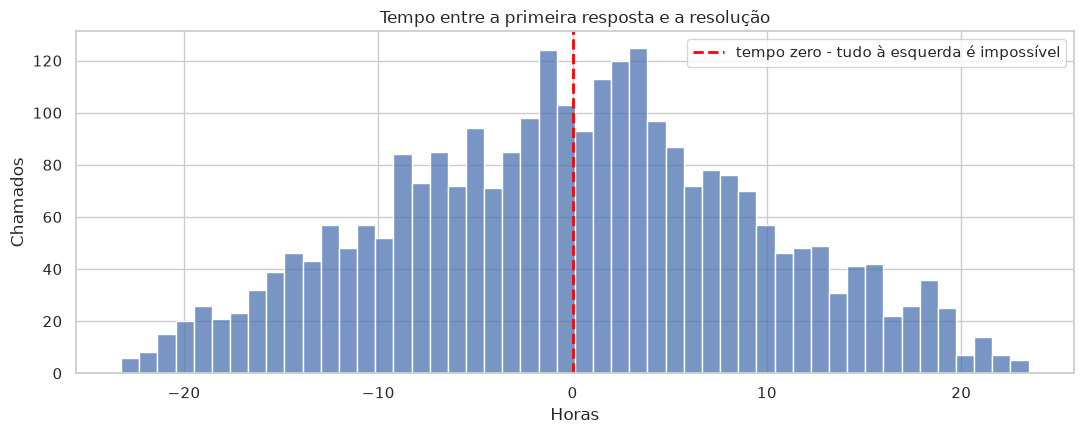

In [17]:
titulo("3. ANOMALIAS - valores que não deveriam existir")

print("3.1 Chamados resolvidos ANTES da primeira resposta")
anomalos = df[df["tempo_inconsistente"]]
print(f"     {len(anomalos)} chamados "
      f"({len(anomalos) / df['horas_ate_resolucao'].notna().sum() * 100:.1f}% dos fechados)")
print(f"     Tempo mais negativo registrado: {df['horas_ate_resolucao'].min():.1f} horas")

print("\n3.2 Placeholder não substituído nas descrições")
print(f"     {df['Ticket Description'].str.contains(r'{product_purchased}', regex=False).sum()} "
      f"de {len(df)} descrições (100%)")

print("\n3.3 Descrições repetidas")
repetidas = df["Ticket Description"].duplicated().sum()
print(f"     {repetidas} descrições repetem outra já existente")
inicio_comum = "I'm having an issue with the {product_purchased}. Please assist."
mesma_abertura = df["Ticket Description"].str.startswith(inicio_comum, na=False)
print(f"     {mesma_abertura.sum()} chamados ({mesma_abertura.mean() * 100:.1f}%) começam com")
print(f"     exatamente o mesmo texto: \"{inicio_comum}\"")
print("\n     E esses chamados se distribuem assim entre as cinco intenções:")
print(df.loc[mesma_abertura, "Ticket Type"].value_counts().to_string())

print("\n3.4 Satisfação registrada em chamado não fechado")
inconsistencia = df[
    (df["Ticket Status"] != "Closed") & df["Customer Satisfaction Rating"].notna()
]
print(f"     {len(inconsistencia)} chamados (esperado: 0)")

# Visualização da anomalia principal
plt.figure(figsize=(11, 4.5))
sns.histplot(df["horas_ate_resolucao"].dropna(), bins=50, color="#4c72b0")
plt.axvline(0, color="red", linestyle="--", linewidth=2,
            label="tempo zero - tudo à esquerda é impossível")
plt.title("Tempo entre a primeira resposta e a resolução")
plt.xlabel("Horas")
plt.ylabel("Chamados")
plt.legend()
plt.tight_layout()
plt.show()

## Observações - outliers e anomalias

### Outliers: quase nenhum, e o único caso tem explicação

| Variável | Outliers pelo IQR | \|z\| > 3 |
|---|---|---|
| `Customer Age` | 0 | 0 |
| `Customer Satisfaction Rating` | 0 | 0 |
| `dias_desde_a_compra` | 0 | 0 |
| `horas_ate_resolucao` | 0 | 0 |
| `descricao_palavras` | **417 (4,92%)** | 18 |

Quatro das cinco variáveis numéricas não têm nenhum valor extremo - nem pelo IQR, nem pelo
escore-z. Isso parece bom, mas não é: dados reais têm outliers. Sempre aparece o cliente que
escreve um textão, o chamado que demora dez vezes mais que a média, a nota fora da curva. A
ausência total de cauda é o que se espera de um sorteio uniforme dentro de uma faixa fechada.

A exceção é `descricao_palavras`, e vale explicar de onde ela vem: essa variável é calculada sobre
a `descricao_corrigida`, ou seja, sobre o texto depois de substituirmos o placeholder pelo nome
real do produto. Como os nomes têm tamanhos diferentes - "Canon EOS" tem duas palavras,
"Philips Hue Lights" tem três -, a substituição espalha um pouco a contagem e empurra alguns
registros para fora do intervalo do IQR.

Ou seja: esses 417 outliers foram criados pela nossa própria etapa de limpeza, não pela
variação de como os clientes escrevem. No texto original, com o placeholder intacto, a
distribuição é ainda mais estreita. É um bom lembrete de que transformação de dado também produz
artefato, e que vale sempre saber de onde veio cada valor.

### Anomalias: essas sim, e são graves

| Anomalia | Ocorrências | Por que é impossível |
|---|---|---|
| Resolução antes da primeira resposta | **1.365** (49,3% dos fechados) | Não dá para resolver um chamado antes de respondê-lo |
| Placeholder `{product_purchased}` no texto | **8.469** (100%) | A variável de template não foi substituída na geração |
| Mesmo texto de abertura repetido | **5.868** (69,3%) | Clientes diferentes não escrevem a mesma frase |
| Satisfação em chamado não fechado | 0 | (esse é o único que está coerente) |

A terceira linha é a mais séria para o objetivo do projeto. Dois terços dos chamados começam com
a frase idêntica *"I'm having an issue with the {product_purchased}. Please assist."* - e esses
chamados estão distribuídos quase igualmente entre as cinco intenções.

Isto é: o mesmo texto aparece rotulado com cinco respostas diferentes. Nenhum modelo de
classificação, por mais sofisticado, consegue aprender a separar classes a partir de exemplos
idênticos com rótulos distintos. Esse ponto volta na próxima seção.

---
# 1.8 Documentação do EDA e conclusões

## Problema

Precisamos construir um classificador que descubra a intenção de um chamado de suporte
(`Ticket Type`) a partir da mensagem escrita pelo cliente (`Ticket Description`). Esse
classificador é o núcleo do sistema de atendimento do projeto.

A pergunta que este EDA precisava responder, portanto, era direta: os dados que escolhemos
sustentam esse modelo?

## Dados

| Item | Valor |
|---|---|
| Dataset | Customer Support Ticket Dataset (Kaggle, autor suraj520) |
| Registros | 8.469 chamados |
| Colunas | 17 (2 numéricas nativas, 7 categóricas, 3 temporais, texto livre e identificadores) |
| Variável-alvo | `Ticket Type` - 5 classes, perfeitamente balanceadas (19,3% a 20,7%) |
| Ausentes | Estruturais: dependem do `Ticket Status`, e por isso foram mantidos como `NaN` |
| Preparação | Datas convertidas, placeholder corrigido em coluna nova, 4 variáveis derivadas criadas |

## Análise

O que fizemos e o que cada etapa mostrou:

| Etapa | Método | Resultado |
|---|---|---|
| Qualidade | Cruzamento de ausentes com status | Ausência é estrutural, não aleatória |
| Qualidade | Coerência entre timestamps | **49,3%** dos fechados com tempo negativo |
| Univariada | Distribuições de 7 categóricas e 5 numéricas | **Todas** próximas da uniforme |
| Multivariada | Heatmap de Pearson e Spearman | Correlação máxima **\|r\| ≈ 0,04** |
| Multivariada | Qui-quadrado `Priority` × `Type` | p = 0,561 - independentes |
| Multivariada | Qui-quadrado `Subject` × `Type` | p = 0,981 - independentes |
| Hipóteses | Mann-Whitney (H1) | p = 0,556 - sem diferença |
| Hipóteses | Mann-Whitney (H2) | p = 0,323 - sem diferença |
| Hipóteses | Mann-Whitney (H3) | p = 0,216 - sem diferença |
| Outliers | IQR e escore-z | Nenhum outlier em 4 das 5 variáveis numéricas |
| Anomalias | Inspeção do texto | **69,3%** dos chamados com o mesmo texto de abertura |

## Insights principais

**1. O dataset é sintético, e as colunas foram geradas de forma independente umas das outras.**
Não é uma impressão: são seis evidências que apontam para o mesmo lugar - correlação máxima de
0,04 entre variáveis distintas, uniformidade em todas as categóricas, independência qui-quadrado
em todos os pares testados, ausência de outliers em quatro das cinco variáveis numéricas (e o
único caso que aparece foi criado pela nossa etapa de limpeza), metade dos tempos logicamente
impossíveis e 100% dos textos com placeholder não resolvido.

**2. Nenhuma das três hipóteses encontrou efeito real.** H1 e H3 foram sustentadas, H2 não.
Mas o motivo de H1 e H3 se sustentarem não é o que supúnhamos: não é um traço do comportamento dos
clientes, é que as variáveis simplesmente não conversam entre si por construção.

**3. O texto não separa as classes.** Dois terços dos chamados compartilham a mesma frase de
abertura, distribuída igualmente entre as cinco intenções. Um classificador não tem do que se
agarrar.

**4. Os valores ausentes seriam uma armadilha num modelo.** `Resolution`, `Time to Resolution` e
`Customer Satisfaction Rating` só existem em chamados já fechados. Usá-las como features seria
*data leakage* clássico: informação que só aparece **depois** do desfecho que queremos prever.

**5. Descobrir isso agora é o resultado mais valioso deste EDA.** Chegamos aqui com testes
estatísticos simples, antes de investir em engenharia de features, arquitetura de modelo ou ajuste
de hiperparâmetros. É exatamente para isso que a análise exploratória existe.

## Limitações da análise

- Por ser um dataset sintético, nada do que concluímos se generaliza para o comportamento real
  de clientes de suporte. As análises descrevem como os dados foram gerados, não o domínio.
- Os testes de hipótese com satisfação usam só os 2.769 chamados fechados, único subconjunto
  onde a nota existe.
- Não rejeitar H₀ não prova que os grupos são iguais - prova que não encontramos diferença.
  Com n ≈ 700 por grupo temos poder para detectar efeitos moderados, mas efeitos muito pequenos
  poderiam escapar. Como os tamanhos de efeito medidos ficaram em torno de 0,03, a conclusão
  prática não muda.
- `horas_ate_resolucao` é inutilizável como métrica operacional por causa dos valores negativos.

---
# 2. Regressão linear e análise do modelo

Esta seção e a seção 3 foram adicionadas no TP3.

O problema principal do projeto é de classificação, mas aqui a proposta é treinar uma regressão
linear para fechar a parte estatística e ver, na prática, o que um modelo linear consegue tirar
desses dados. A regressão precisa de um alvo numérico, então usamos uma variável derivada do
próprio dataset.

## 2.1 Variável alvo e variáveis de entrada

**Variável alvo: `descricao_palavras`**, a quantidade de palavras da descrição do chamado. Ela foi
criada na etapa 1.4, depois da correção do placeholder, e já tinha sido usada na H1. Escolhemos
essa variável porque ela vem do texto escrito pelo cliente, que é a parte do dataset que mais
importa para o projeto, e porque não tem nenhum valor ausente.

A pergunta que a regressão tenta responder é: **dá para prever o tamanho da mensagem a partir das
informações do cliente e do chamado?**

**Variáveis de entrada:** usamos só colunas que já existem no momento em que o chamado é aberto.

| Variável | Tipo | Tratamento |
|---|---|---|
| `Customer Age` | Numérica | Padronizada (`StandardScaler`) |
| `Customer Gender` | Categórica (3 categorias) | One-hot |
| `Product Purchased` | Categórica (42 categorias) | One-hot |
| `Ticket Type` | Categórica (5 categorias) | One-hot |
| `Ticket Subject` | Categórica (16 categorias) | One-hot |
| `Ticket Priority` | Categórica (4 categorias) | One-hot |
| `Ticket Channel` | Categórica (4 categorias) | One-hot |

O que ficou de fora e por quê:

- `Ticket Status`, `Resolution`, `First Response Time`, `Time to Resolution` e
  `Customer Satisfaction Rating`: só são conhecidas depois do atendimento. Usar essas colunas seria
  o mesmo *data leakage* que apontamos no insight 4 da etapa 1.8.
- `Ticket ID`, `Customer Name` e `Customer Email`: são identificadores e não dizem nada sobre o
  chamado.
- `Date of Purchase`: a data sozinha não tem significado para o modelo, e a variável que criamos a
  partir dela (`dias_desde_a_compra`) depende de `First Response Time`, que falta nos chamados
  abertos.
- O próprio texto (`Ticket Description`): o alvo é calculado a partir dele, então usar o texto
  como entrada seria circular.

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ALVO = "descricao_palavras"
ENTRADAS_CATEGORICAS = ["Customer Gender", "Product Purchased", "Ticket Type",
                        "Ticket Subject", "Ticket Priority", "Ticket Channel"]
ENTRADAS_NUMERICAS = ["Customer Age"]

X = df[ENTRADAS_CATEGORICAS + ENTRADAS_NUMERICAS]
y = df[ALVO]

titulo("Variável alvo: descricao_palavras")
print(y.describe().round(2).to_string())
print(f"\nValores ausentes no alvo: {y.isna().sum()} | nas entradas: {X.isna().sum().sum()}")


Variável alvo: descricao_palavras
count    8469.00
mean       48.54
std         8.62
min        21.00
25%        45.00
50%        51.00
75%        55.00
max        67.00

Valores ausentes no alvo: 0 | nas entradas: 0


## 2.2 Treinamento do modelo

O processo de treinamento foi este:

1. **Divisão em treino (80%) e teste (20%)**, com `random_state=42`, antes de qualquer ajuste. O
   conjunto de teste fica guardado e só é usado na avaliação final.
2. **Pré-processamento dentro de um `Pipeline`.** As categóricas passam pelo `OneHotEncoder`: cada
   categoria vira uma coluna de 0 e 1, porque a regressão só trabalha com números e não existe
   ordem entre, por exemplo, os canais de atendimento. A idade passa pelo `StandardScaler`. Como
   tudo está dentro do `Pipeline`, o encoder e o scaler aprendem só com os dados de treino.
3. **Regressão linear por mínimos quadrados** (`LinearRegression`), que encontra os coeficientes
   que minimizam a soma dos erros ao quadrado no treino.

In [19]:
def montar_regressao(categoricas, numericas):
    """Pipeline com o pré-processamento e a regressão linear."""
    transformacoes = [("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas)]
    if numericas:
        transformacoes.append(("numericas", StandardScaler(), numericas))

    return Pipeline([
        ("pre_processamento", ColumnTransformer(transformacoes)),
        ("regressao", LinearRegression()),
    ])


X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42
)

modelo_regressao = montar_regressao(ENTRADAS_CATEGORICAS, ENTRADAS_NUMERICAS)
modelo_regressao.fit(X_treino, y_treino)

titulo("Treinamento")
print(f"Chamados no treino: {len(X_treino)} | no teste: {len(X_teste)}")
colunas = modelo_regressao.named_steps["pre_processamento"].get_feature_names_out()
print(f"Colunas depois do one-hot e da padronização: {len(colunas)}")
print(f"Intercepto: {modelo_regressao.named_steps['regressao'].intercept_:.2f} palavras")


Treinamento
Chamados no treino: 6775 | no teste: 1694
Colunas depois do one-hot e da padronização: 75
Intercepto: 48.57 palavras


## 2.3 Avaliação: R² e RMSE

As duas métricas pedidas medem coisas diferentes:

- **R²** é a fração da variação do alvo que o modelo consegue explicar. Vale 1 quando o modelo
  acerta tudo, 0 quando ele não é melhor do que prever sempre a média, e fica negativo quando é
  pior do que isso.
- **RMSE** é o erro típico das previsões, na mesma unidade do alvo (aqui, palavras). Para ter uma
  referência, comparamos com o desvio-padrão do alvo, que é exatamente o RMSE de quem prevê sempre
  a média.

In [20]:
def avaliar(nome, y_real, y_previsto):
    r2 = r2_score(y_real, y_previsto)
    rmse = np.sqrt(mean_squared_error(y_real, y_previsto))
    print(f"{nome:8s} R² = {r2:7.4f} | RMSE = {rmse:.3f} palavras")
    return r2, rmse


titulo("R² e RMSE")
previsto_treino = modelo_regressao.predict(X_treino)
previsto_teste = modelo_regressao.predict(X_teste)
r2_treino, rmse_treino = avaliar("Treino", y_treino, previsto_treino)
r2_teste, rmse_teste = avaliar("Teste", y_teste, previsto_teste)

desvio_teste = y_teste.std(ddof=0)
print(f"\nDesvio-padrão do alvo no teste: {desvio_teste:.3f} palavras")
print("(é o RMSE que teríamos prevendo sempre a média, sem modelo nenhum)")
print(f"O modelo reduz o erro em só {(1 - rmse_teste / desvio_teste) * 100:.2f}% em relação a isso.")
print(f"\nPrevisões no teste: de {previsto_teste.min():.1f} a {previsto_teste.max():.1f} palavras")
print(f"Valores reais no teste: de {y_teste.min()} a {y_teste.max()} palavras")

titulo("De onde vem o pouco que o modelo acerta?")
for nome, categoricas, numericas in [
    ("Só Product Purchased", ["Product Purchased"], []),
    ("Todas menos Product Purchased",
     [c for c in ENTRADAS_CATEGORICAS if c != "Product Purchased"], ENTRADAS_NUMERICAS),
]:
    parcial = montar_regressao(categoricas, numericas).fit(X_treino, y_treino)
    print(f"{nome:30s} R² no teste = {r2_score(y_teste, parcial.predict(X_teste)):7.4f}")

palavras_do_produto = df["Product Purchased"].str.split().str.len()
vezes_do_placeholder = df["Ticket Description"].str.count(r"\{product_purchased\}")
print(f"\nCorrelação entre o nº de palavras do nome do produto e o alvo: "
      f"{palavras_do_produto.corr(y):.3f}")
print(f"Correlação entre as vezes que o placeholder aparece e o alvo: "
      f"{vezes_do_placeholder.corr(y):.3f}")


R² e RMSE
Treino   R² =  0.0273 | RMSE = 8.439 palavras
Teste    R² =  0.0059 | RMSE = 8.836 palavras

Desvio-padrão do alvo no teste: 8.862 palavras
(é o RMSE que teríamos prevendo sempre a média, sem modelo nenhum)
O modelo reduz o erro em só 0.30% em relação a isso.

Previsões no teste: de 44.9 a 52.7 palavras
Valores reais no teste: de 21 a 65 palavras

De onde vem o pouco que o modelo acerta?
Só Product Purchased           R² no teste =  0.0076
Todas menos Product Purchased  R² no teste = -0.0018

Correlação entre o nº de palavras do nome do produto e o alvo: 0.123
Correlação entre as vezes que o placeholder aparece e o alvo: 0.159


### O que os números dizem

| Métrica | Treino | Teste |
|---|---|---|
| R² | 0,0273 | **0,0059** |
| RMSE | 8,44 palavras | **8,84 palavras** |

**R²:** no teste o modelo explica **0,6%** da variação do tamanho das mensagens. Na prática,
isso é quase zero. As 75 colunas de entrada quase não dizem nada sobre quantas palavras o cliente vai escrever.
A diferença entre treino (2,7%) e teste (0,6%) mostra ainda que parte do pouco que o modelo
aprendeu no treino era ruído, que não se repetiu em dados novos.

**RMSE:** o erro típico no teste é de **8,84 palavras**, numa variável com média de 48,5 palavras.
Prevendo sempre a média, sem modelo nenhum, o erro seria de 8,86 palavras. O modelo reduz o erro em
só 0,3%. Além disso, as previsões ficam todas espremidas entre 44,9 e 52,7 palavras, enquanto os
valores reais vão de 21 a 65: o modelo nunca arrisca prever uma mensagem curta ou longa.

**De onde vem o pouco que o modelo acerta.** Separando as entradas, o R² no teste fica em 0,0076
só com `Product Purchased` e em -0,0018 com todas as outras juntas. Ou seja, o único sinal vem do
produto, e o motivo é a nossa própria limpeza: na etapa 1.4 trocamos o placeholder
`{product_purchased}` pelo nome do produto, que pode ter de 1 a 4 palavras e aparece de 1 a 5 vezes
no texto. Um produto com nome mais comprido gera, por construção, uma descrição mais longa
(correlação de 0,12). O que o modelo aprendeu foi esse efeito da limpeza, e nada sobre o
comportamento dos clientes. Tipo de chamado, prioridade, canal, assunto, gênero e idade não ajudam em nada, o que
bate com a independência entre as colunas que encontramos no EDA.

## 2.4 Análise dos resíduos

O resíduo é a diferença entre o valor real e o valor previsto. Olhamos para eles de duas formas:

- **Residual Plot:** resíduo contra o valor previsto. Num modelo bem ajustado, os pontos ficam
  espalhados por igual em volta do zero, sem formato.
- **Q-Q Plot:** compara os quantis dos resíduos com os de uma distribuição normal. Se os resíduos
  forem normais, os pontos ficam em cima da linha vermelha.

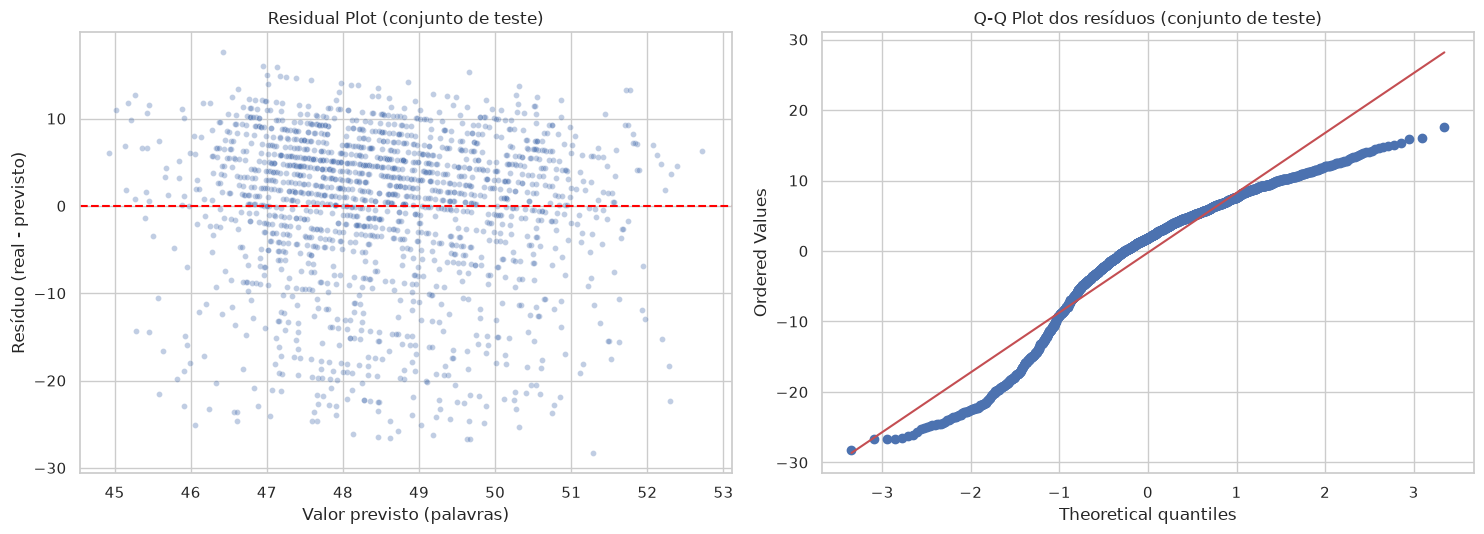


Resumo dos resíduos
Média: -0.236 | desvio-padrão: 8.835
Mínimo: -28.3 | máximo: 17.6
Assimetria: -0.991 | curtose (excesso): 0.419
Shapiro-Wilk: W = 0.9205 | p = 5.43e-29
Resíduos abaixo de -15 palavras: 162 | acima de +15: 4


In [21]:
residuos = y_teste - previsto_teste

fig, eixos = plt.subplots(1, 2, figsize=(15, 5.5))

sns.scatterplot(x=previsto_teste, y=residuos, alpha=0.35, s=18, ax=eixos[0])
eixos[0].axhline(0, color="red", linestyle="--")
eixos[0].set(title="Residual Plot (conjunto de teste)",
             xlabel="Valor previsto (palavras)", ylabel="Resíduo (real - previsto)")

stats.probplot(residuos, dist="norm", plot=eixos[1])
eixos[1].set_title("Q-Q Plot dos resíduos (conjunto de teste)")

plt.tight_layout()
plt.show()

titulo("Resumo dos resíduos")
print(f"Média: {residuos.mean():.3f} | desvio-padrão: {residuos.std():.3f}")
print(f"Mínimo: {residuos.min():.1f} | máximo: {residuos.max():.1f}")
print(f"Assimetria: {stats.skew(residuos):.3f} | curtose (excesso): {stats.kurtosis(residuos):.3f}")
w, p_shapiro = stats.shapiro(residuos)
print(f"Shapiro-Wilk: W = {w:.4f} | p = {p_shapiro:.2e}")
print(f"Resíduos abaixo de -15 palavras: {(residuos < -15).sum()} | acima de +15: {(residuos > 15).sum()}")

### O que os gráficos mostram

**Residual Plot.** Não aparece nenhuma curva ou funil: os resíduos não crescem nem diminuem
conforme o valor previsto. Isso indica que o problema não é a forma do modelo (não falta, por
exemplo, um termo quadrático). O que chama atenção é a escala: as previsões ocupam só a faixa de 45 a 53
palavras (eixo x), enquanto os resíduos vão de -28 a +18 (eixo y). O modelo dá quase a mesma resposta para todo mundo, e o erro
é praticamente a própria variação do alvo. Também dá para ver que a nuvem é desequilibrada: há 162
resíduos abaixo de -15 palavras e só 4 acima de +15.

**Q-Q Plot.** Os pontos formam um "S" e se afastam da linha nas duas pontas:

- **Na ponta esquerda**, os pontos ficam abaixo da linha: há mais erros negativos grandes do que
  uma normal teria. São as mensagens curtas (20 e poucas palavras), que o modelo sempre
  superestima, porque nunca prevê menos de 45.
- **Na ponta direita**, os pontos ficam abaixo da linha também: os erros positivos param em +18,
  bem antes do que uma normal permitiria. Isso acontece porque o texto tem um limite de tamanho
  (o maior tem 67 palavras).

Os números confirmam: assimetria de -0,99, e o teste de Shapiro-Wilk rejeita a normalidade com
folga (p = 5,4 × 10⁻²⁹). A média dos resíduos fica perto de zero (-0,24), então o modelo não erra
sistematicamente para um lado, mas a distribuição dos erros não é normal. Isso vem do próprio
alvo, que já é assimétrico à esquerda: a mediana (51 palavras) fica acima da média (48,5), metade
dos textos tem entre 45 e 55 palavras e existe uma cauda de textos curtos que desce até 21.

## 2.5 Limitações do modelo

1. **As entradas não explicam o alvo.** Com R² de 0,006 no teste e RMSE praticamente igual ao
   desvio-padrão, o modelo não é melhor do que prever a média. O problema não está no ajuste, porque o
   EDA já mostrou que as colunas foram geradas de forma independente, e uma regressão não cria relação
   onde ela não existe.
2. **O único sinal é um artefato da limpeza.** O pouco que o modelo acerta vem do tamanho do nome
   do produto, inserido por nós no lugar do placeholder. Se tivéssemos usado o texto original, nem
   esse efeito existiria.
3. **Os resíduos não são normais.** A assimetria e as caudas fora da linha no Q-Q Plot quebram uma
   das hipóteses da regressão linear. Os coeficientes continuam válidos como estimativa, mas
   intervalos de confiança e testes sobre eles, que dependem da normalidade, deixam de ser
   confiáveis.
4. **O modelo não consegue prever os extremos.** As previsões ficam entre 45 e 53 palavras, então
   toda mensagem curta é superestimada em até 28 palavras.
5. **Sobreajuste leve.** O R² cai de 0,027 no treino para 0,006 no teste. Com 75 colunas e quase
   nenhum sinal, parte dos coeficientes se ajustou ao ruído do treino.
6. **O alvo é discreto.** O número de palavras é um inteiro entre 21 e 67, e a regressão devolve
   valores contínuos como 48,37 palavras.

## 2.6 Por que esse modelo não representa o problema de classificação

Mesmo que o modelo fosse bom, ele não resolveria o problema do projeto:

- **Ele responde outra pergunta.** A regressão prevê *quantas palavras* a mensagem tem. O sistema
  precisa saber *o que o cliente quer*. Saber que um chamado tem 50 palavras não diz se é um pedido
  de reembolso ou um problema técnico.
- **A intenção aparece do lado errado.** Aqui `Ticket Type` é uma das **entradas**. No problema
  do projeto a intenção é justamente o que não sabemos e queremos descobrir.
- **A saída é um número, não uma categoria.** A regressão devolve qualquer valor real, e a
  intenção é uma de cinco categorias sem ordem entre si.
- **A entrada do problema real é o texto.** O classificador vai receber a mensagem do cliente, e
  não idade, canal e prioridade.

A seção seguinte formaliza o problema de classificação e mostra, com os dados, o que acontece
quando tentamos usar regressão linear para prever a intenção diretamente.

---
# 3. Formalização do problema de classificação

## A pergunta

> **Dado o texto de uma mensagem de atendimento ao cliente, qual é a intenção do usuário?**

## Entrada (X) e alvo (y)

| | Coluna | O que é |
|---|---|---|
| **X** (entrada) | `Ticket Description` | O texto livre que o cliente escreve ao abrir o chamado. Cada chamado tem um texto |
| **y** (alvo) | `Ticket Type` | A intenção do chamado: uma categoria entre 5 possíveis, sem ordem entre elas |

O modelo recebe só o texto. As outras colunas não entram: ou não estão disponíveis no momento em
que a mensagem chega, ou, como vimos no EDA, não têm relação com a intenção. Para virar entrada de
um modelo, o texto precisa ser transformado em números. Essa parte está definida no planejamento
(`others/planejamento.md`), com o `CountVectorizer`.

**Tipo de problema:** classificação **supervisionada** e **multiclasse**. Supervisionada porque
todos os 8.469 chamados já vêm com a intenção rotulada. Multiclasse porque são cinco classes
possíveis e cada chamado pertence a exatamente uma.

## As classes de intenção

| Classe (`Ticket Type`) | O que o cliente quer |
|---|---|
| `Refund request` | Receber o dinheiro de volta |
| `Technical issue` | Resolver um defeito ou falha do produto |
| `Cancellation request` | Cancelar o produto ou a assinatura |
| `Product inquiry` | Tirar uma dúvida sobre o produto |
| `Billing inquiry` | Entender ou contestar uma cobrança |

## Distribuição das classes no dataset


Distribuição das classes de intenção (Ticket Type)


,Chamados,Percentual (%)
Ticket Type,,
Refund request,1752,20.69
Technical issue,1747,20.63
Cancellation request,1695,20.01
Product inquiry,1641,19.38
Billing inquiry,1634,19.29
Total,8469,100.00


Classe mais frequente: Refund request (1752 chamados)
Classe menos frequente: Billing inquiry (1634 chamados)
Razão entre a maior e a menor: 1.07

Qui-quadrado de aderência à distribuição uniforme: 7.43 (4 g.l.) | p-valor = 0.1149


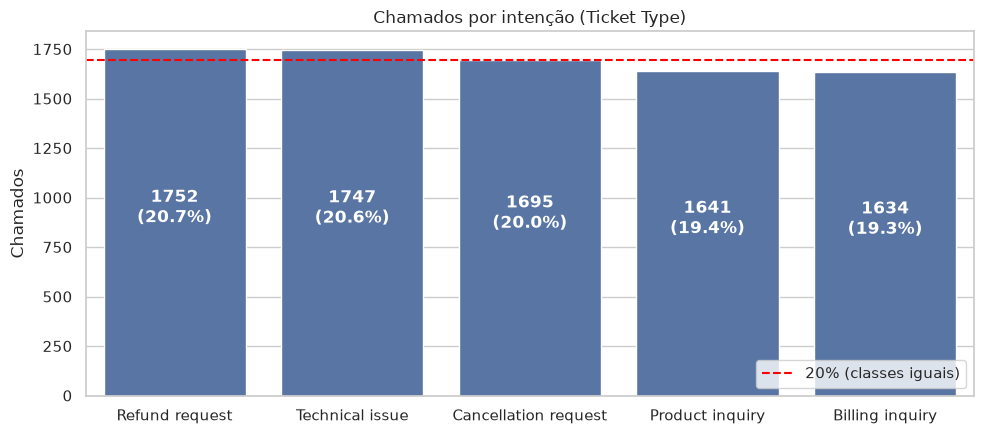

In [22]:
titulo("Distribuição das classes de intenção (Ticket Type)")
contagem = df["Ticket Type"].value_counts()
distribuicao = pd.DataFrame({
    "Chamados": contagem,
    "Percentual (%)": (contagem / contagem.sum() * 100).round(2),
})
distribuicao.loc["Total"] = [contagem.sum(), 100.0]
distribuicao["Chamados"] = distribuicao["Chamados"].astype(int)
display(distribuicao)

print(f"Classe mais frequente: {contagem.idxmax()} ({contagem.max()} chamados)")
print(f"Classe menos frequente: {contagem.idxmin()} ({contagem.min()} chamados)")
print(f"Razão entre a maior e a menor: {contagem.max() / contagem.min():.2f}")

# Qui-quadrado de aderência: as 5 classes têm a mesma frequência?
qui2_classes, p_classes = stats.chisquare(contagem)
print(f"\nQui-quadrado de aderência à distribuição uniforme: "
      f"{qui2_classes:.2f} (4 g.l.) | p-valor = {p_classes:.4f}")

fig, eixo = plt.subplots(figsize=(10, 4.5))
sns.barplot(x=contagem.index, y=contagem.values, color="#4C72B0", ax=eixo)
eixo.axhline(len(df) / 5, color="red", linestyle="--", label="20% (classes iguais)")
for posicao, valor in enumerate(contagem.values):
    eixo.text(posicao, valor / 2, f"{valor}\n({valor / len(df):.1%})",
              ha="center", color="white", fontweight="bold")
eixo.set(title="Chamados por intenção (Ticket Type)", xlabel="", ylabel="Chamados")
eixo.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Existe alguma classe significativamente mais frequente?

**Não.** A classe mais frequente (`Refund request`, 20,69%) tem só 1,07 vez o tamanho da menos
frequente (`Billing inquiry`, 19,29%). Para não depender só do olho, testamos com o qui-quadrado
de aderência se as cinco classes poderiam ter a mesma frequência: **p = 0,115**, acima de 0,05.
Ou seja, a diferença entre as classes é do tamanho que se espera por acaso, e não temos evidência de
que alguma intenção seja mais frequente que as outras.

Na prática isso significa que:

- não precisamos de técnicas de balanceamento (como oversampling ou peso por classe);
- um modelo que chuta sempre a classe mais comum acerta só **20,7%**, e essa é a régua mínima que
  o classificador precisa superar;
- a acurácia é uma métrica justa aqui, porque nenhuma classe domina o resultado.

## Por que é um problema de classificação

O alvo `Ticket Type` é uma **variável categórica nominal**: um conjunto fechado de cinco rótulos,
sem ordem e sem distância entre eles. Não faz sentido dizer que `Billing inquiry` é "maior" que
`Refund request`, nem que a distância entre `Product inquiry` e `Technical issue` é 2. O que o
sistema precisa é escolher **um** desses cinco rótulos para cada mensagem, e é exatamente isso que
um classificador faz. Ele ainda pode devolver a probabilidade de cada classe, o que permite mandar
para um atendente humano os chamados em que o modelo está em dúvida.

## Por que a regressão linear não é adequada

Para usar regressão linear, teríamos que transformar as intenções em números (0 a 4) e prever esse
número. Isso cria quatro problemas:

1. **A ordem é inventada.** A regressão trata o 3 como "entre" o 2 e o 4. Se o modelo fica em
   dúvida entre a classe 0 e a classe 4, a média dá 2, que é uma terceira intenção sem nada a ver
   com as outras duas.
2. **A saída não é uma classe.** A regressão pode devolver 2,6 ou -7, que não correspondem a
   nenhuma intenção.
3. **Não existe probabilidade por classe**, então o sistema não consegue saber quando o modelo
   está em dúvida.
4. **A função de perda mede a coisa errada.** O erro ao quadrado pune mais quando o número previsto
   está "longe" do certo, mas confundir reembolso com cancelamento não é menos grave do que
   confundir reembolso com problema técnico.

Para mostrar isso nos dados, forçamos uma regressão linear sobre a intenção numerada, usando o
texto como entrada (transformado com o `CountVectorizer`):

In [23]:
titulo("Forçando uma regressão linear para prever a intenção")

# A regressão precisa de um número, então numeramos as classes em ordem alfabética
CODIGOS = {classe: codigo for codigo, classe in enumerate(sorted(contagem.index))}
print("Numeração usada:", CODIGOS)

texto_treino, texto_teste, tipo_treino, tipo_teste = train_test_split(
    df["Ticket Description"], df["Ticket Type"], test_size=0.2, random_state=42,
    stratify=df["Ticket Type"],
)


def regressao_sobre_a_intencao(codigos):
    """Treina a regressão no texto e devolve o número previsto e a classe arredondada."""
    modelo = Pipeline([("texto", CountVectorizer()), ("regressao", LinearRegression())])
    modelo.fit(texto_treino, tipo_treino.map(codigos))
    numero = modelo.predict(texto_teste)
    por_codigo = {codigo: classe for classe, codigo in codigos.items()}
    classe = pd.Series(np.clip(np.round(numero), 0, 4).astype(int)).map(por_codigo)
    return numero, classe.to_numpy()


numero_previsto, classe_prevista = regressao_sobre_a_intencao(CODIGOS)
fora = ((numero_previsto < 0) | (numero_previsto > 4)).mean()
print(f"\nNúmeros previstos vão de {numero_previsto.min():.2f} a {numero_previsto.max():.2f}")
print(f"Previsões fora do intervalo 0 a 4 (não são classe nenhuma): {fora:.1%}")
print(f"Acerto depois de arredondar: {(classe_prevista == tipo_teste.to_numpy()).mean():.1%}")
print(f"Acerto chutando sempre a classe mais comum: {contagem.max() / len(df):.1%}")

# Mesma regressão, mesmos dados, só trocando a numeração das classes
CODIGOS_OUTRA_ORDEM = {classe: codigo for codigo, classe in
                       enumerate(["Billing inquiry", "Technical issue", "Refund request",
                                  "Cancellation request", "Product inquiry"])}
_, classe_outra_ordem = regressao_sobre_a_intencao(CODIGOS_OUTRA_ORDEM)
print(f"\nTrocando só a numeração para {CODIGOS_OUTRA_ORDEM},")
print(f"a classe prevista muda em {(classe_prevista != classe_outra_ordem).mean():.1%} dos chamados de teste.")


Forçando uma regressão linear para prever a intenção
Numeração usada: {'Billing inquiry': 0, 'Cancellation request': 1, 'Product inquiry': 2, 'Refund request': 3, 'Technical issue': 4}



Números previstos vão de -19.72 a 17.56
Previsões fora do intervalo 0 a 4 (não são classe nenhuma): 26.6%
Acerto depois de arredondar: 20.4%
Acerto chutando sempre a classe mais comum: 20.7%



Trocando só a numeração para {'Billing inquiry': 0, 'Technical issue': 1, 'Refund request': 2, 'Cancellation request': 3, 'Product inquiry': 4},
a classe prevista muda em 81.1% dos chamados de teste.


### O que a demonstração mostrou

| O que medimos | Resultado |
|---|---|
| Faixa dos números previstos | de -19,72 a 17,56, para um alvo que só vai de 0 a 4 |
| Previsões fora do intervalo 0 a 4 | **26,6%**, que não correspondem a intenção nenhuma |
| Acerto depois de arredondar | 20,4%, abaixo dos 20,7% de chutar sempre a classe mais comum |
| Classe prevista que muda ao trocar só a numeração | **81,1%** dos chamados de teste |

O último resultado é o que mais pesa contra a regressão. Com os mesmos dados e o mesmo modelo, só
mudar a ordem em que numeramos as classes muda a resposta em 4 de cada 5 chamados. Um modelo cuja resposta depende
de uma escolha arbitrária nossa não serve para o problema. Por isso a intenção vai ser prevista com
um modelo de classificação, como definido no planejamento.

O acerto abaixo do chute trivial também é um aviso que já aparecia no EDA: o texto deste dataset
quase não diferencia as intenções. Trocar a regressão por um classificador resolve os problemas de
**método**, mas não garante um bom resultado, e é por isso que o primeiro passo do Trimestre 2 vai
ser comparar o classificador com esse chute trivial.